#Integrating Financial Metrics and News Sentiment for Stock Price Forecasting: A CRISP-DM Framework

####This notebook analyzes how news sentiment affects stock price movements by combining financial metrics with Reddit headlines sentiment analysis. We implement and compare various machine learning and deep learning models (GradientBoost, LSTM, CNN, CNN-LSTM) to predict price direction for major securities. The goal is to determine whether integrating sentiment data improves forecasting accuracy beyond traditional technical indicators alone.

# CRISP-DM 1 – Business / Data Understanding

In [ ]:
# Run this cell first to fix the NumPy compatibility error

# Downgrade NumPy to a compatible version
!pip uninstall -y numpy
!pip install numpy==1.26.0

# # Restart the runtime
# import IPython
# IPython.Application.instance().kernel.do_shutdown(True)

Found existing installation: numpy 2.0.2
Uninstalling numpy-2.0.2:
  Successfully uninstalled numpy-2.0.2
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.5/58.5 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.2/18.2 MB 110.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
thinc 8.3.6 requires numpy<3.0.0,>=2.0.0, but you have numpy 1.26.0 which is incompatible.


In [ ]:
# # Fix NumPy compatibility issues (run this first if needed)
# !pip uninstall -y numpy
# !pip install numpy==1.26.0

# Library installation
!pip -q install yfinance curl_cffi vaderSentiment tqdm matplotlib seaborn wordcloud plotly --upgrade

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 113.7/113.7 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.4/7.4 MB 65.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.0/126.0 kB 10.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.6/8.6 MB 42.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.8/14.8 MB 79.3 MB/s eta 0:00:00


In [ ]:
# Install SHAP separately
!pip install shap==0.44.1

# Install TensorFlow separately
!pip install tensorflow==2.15.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 535.8/535.8 kB 21.6 MB/s eta 0:00:00
  Attempting uninstall: slicer
    Found existing installation: slicer 0.0.8
    Uninstalling slicer-0.0.8:
      Successfully uninstalled slicer-0.0.8
  Attempting uninstall: shap
    Found existing installation: shap 0.47.2
    Uninstalling shap-0.47.2:
      Successfully uninstalled shap-0.47.2
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 475.3/475.3 MB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 83.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 72.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.6/294.6 kB 31.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 124.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.0/442.0 kB 39.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.4/78.4 kB 8.1 MB/s eta 0:00:00
  Attempting uninstall: wrapt
    Found existing installation: wrapt

In [1]:
# Imports, global constants & random seeds
import os, random, warnings, json, math, gc, time, itertools
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from tqdm.notebook import tqdm
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from wordcloud import WordCloud
from textblob import TextBlob

# Set visual styles
plt.style.use('fivethirtyeight')
sns.set_style('whitegrid')
warnings.filterwarnings('ignore')

# Set seeds for reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)

# CRISP-DM 2 – Data Acquisition (Reddit news)

In [3]:
!pip install vaderSentiment

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.0/126.0 kB 9.7 MB/s eta 0:00:00


In [4]:
# Load and prepare financial news data
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
analyzer = SentimentIntensityAnalyzer()
news_path = 'RedditNews.csv'   # <-- change if file is elsewhere

print("Loading and processing news data...")
raw_news = pd.read_csv(news_path)
raw_news['Date'] = pd.to_datetime(raw_news['Date'])

# Sentiment analysis with VADER
raw_news['compound'] = raw_news['News'].astype(str).apply(lambda x: analyzer.polarity_scores(x)['compound'])
raw_news['positive'] = raw_news['News'].astype(str).apply(lambda x: analyzer.polarity_scores(x)['pos'])
raw_news['negative'] = raw_news['News'].astype(str).apply(lambda x: analyzer.polarity_scores(x)['neg'])
raw_news['neutral'] = raw_news['News'].astype(str).apply(lambda x: analyzer.polarity_scores(x)['neu'])

# Additional sentiment metrics using TextBlob
raw_news['textblob_polarity'] = raw_news['News'].astype(str).apply(lambda x: TextBlob(x).sentiment.polarity)

# Filter for financial news
financial_keywords = ['market', 'stock', 'share', 'investor', 'economy', 'economic', 'finance',
                     'financial', 'trade', 'trading', 'investment', 'fund', 'bank', 'profit']

# Create a column indicating if the news is financial
raw_news['is_financial'] = raw_news['News'].astype(str).apply(
    lambda x: any(keyword in x.lower() for keyword in financial_keywords)
)

# Daily sentiment = mean of compound scores for that calendar day
daily_news = raw_news.groupby('Date', as_index=False).agg({
    'compound': 'mean',
    'positive': 'mean',
    'negative': 'mean',
    'neutral': 'mean',
    'textblob_polarity': 'mean',
    'is_financial': 'sum',
    'News': 'count'
})

daily_news.rename(columns={
    'compound': 'Sentiment',
    'News': 'NewsCount',
    'is_financial': 'FinancialNewsCount'
}, inplace=True)

print(f"Total news headlines: {len(raw_news)}")
print(f"Date range: {raw_news['Date'].min()} to {raw_news['Date'].max()}")
print(f"Financial news headlines: {raw_news['is_financial'].sum()}")
print(f"Unique dates: {len(daily_news)}")
print("\nSample daily sentiment:")
display(daily_news.head())

Loading and processing news data...
Total news headlines: 73608
Date range: 2008-06-08 00:00:00 to 2016-07-01 00:00:00
Financial news headlines: 4704
Unique dates: 2943

Sample daily sentiment:


,Date,Sentiment,positive,negative,neutral,textblob_polarity,FinancialNewsCount,NewsCount
0,2008-06-08,-0.339292,0.03632,0.18592,0.77776,-0.032892,2,25
1,2008-06-09,-0.239752,0.06428,0.16456,0.77112,0.026156,3,25
2,2008-06-10,-0.279236,0.05292,0.20484,0.74228,-0.029106,0,25
3,2008-06-11,-0.130976,0.07592,0.13692,0.78712,-0.014500,0,25
4,2008-06-12,-0.105372,0.07040,0.13892,0.79072,0.036611,0,25


## Visualize Sentiment Distribution

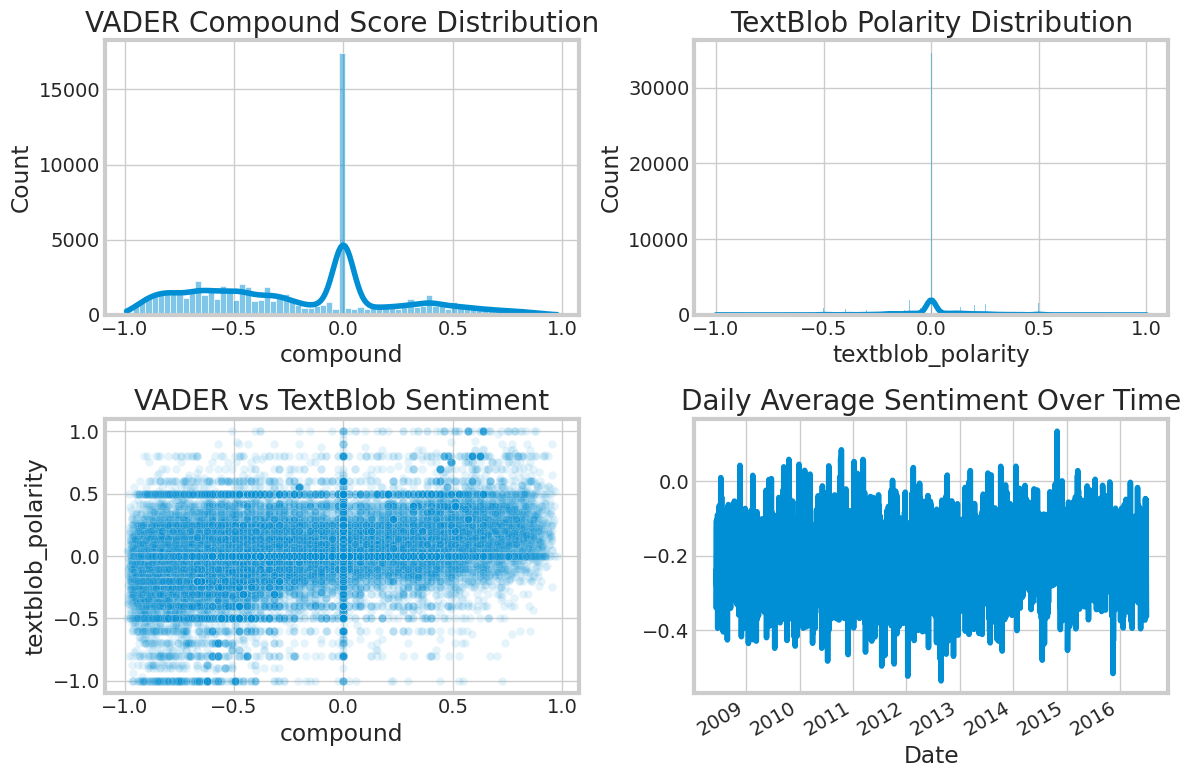

In [5]:
# Visualize the sentiment distribution
plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1)
sns.histplot(raw_news['compound'], kde=True)
plt.title('VADER Compound Score Distribution')

plt.subplot(2, 2, 2)
sns.histplot(raw_news['textblob_polarity'], kde=True)
plt.title('TextBlob Polarity Distribution')

plt.subplot(2, 2, 3)
sns.scatterplot(x='compound', y='textblob_polarity', data=raw_news, alpha=0.1)
plt.title('VADER vs TextBlob Sentiment')

plt.subplot(2, 2, 4)
daily_sentiment = daily_news.set_index('Date')['Sentiment']
daily_sentiment.plot()
plt.title('Daily Average Sentiment Over Time')
plt.tight_layout()
plt.show()

## Create Word Cloud of News Headlines

Generating word cloud of news headlines...


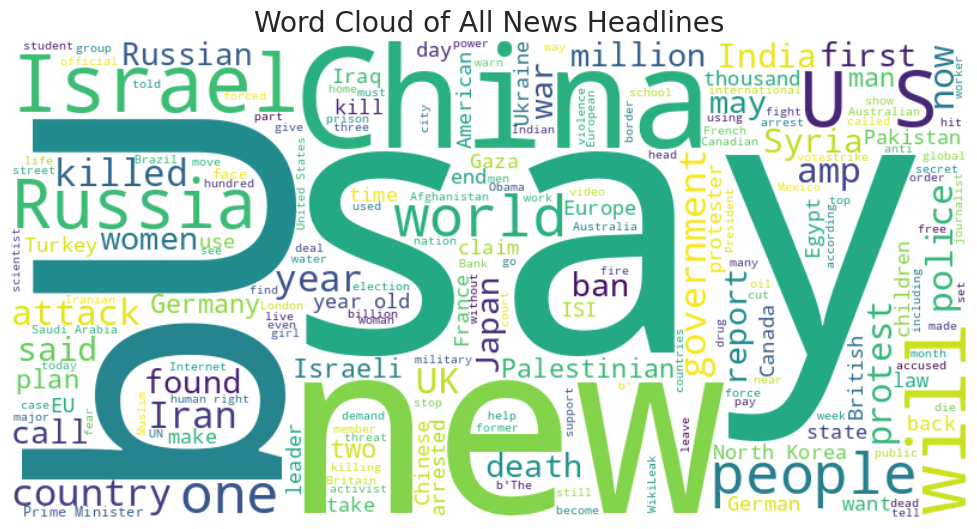

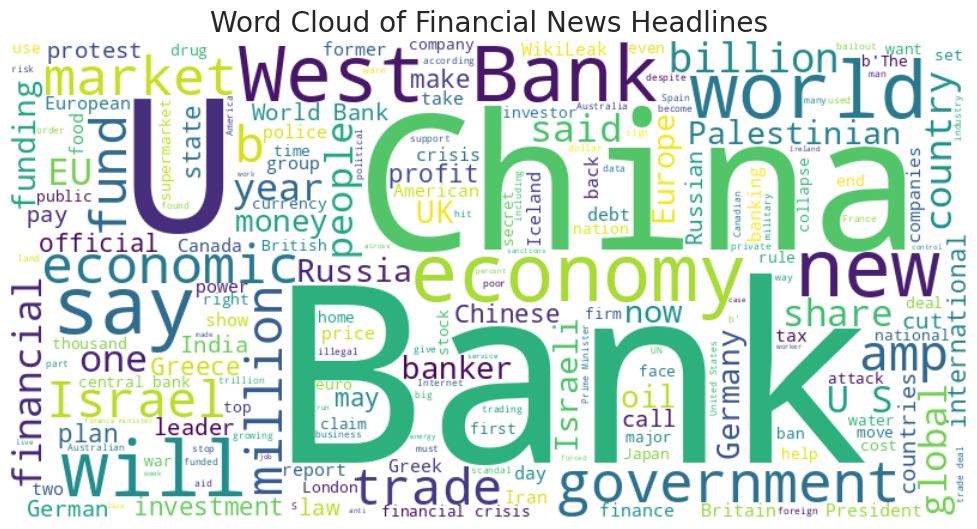

In [6]:
# Create a word cloud of the news
print("Generating word cloud of news headlines...")
def create_wordcloud(text_series, title, max_words=200):
    text = ' '.join(text_series.astype(str).tolist())
    wordcloud = WordCloud(
        background_color='white',
        max_words=max_words,
        contour_width=3,
        contour_color='steelblue',
        width=800,
        height=400
    ).generate(text)

    plt.figure(figsize=(10, 6))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(title)
    plt.tight_layout()
    plt.show()

create_wordcloud(raw_news['News'], 'Word Cloud of All News Headlines')
create_wordcloud(
    raw_news[raw_news['is_financial']]['News'],
    'Word Cloud of Financial News Headlines'
)

# CRISP-DM 2 – Data Acquisition (Stock data)

In [7]:
!pip install curl_cffi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.4/7.4 MB 110.0 MB/s eta 0:00:00


In [8]:
# Patch yfinance and prepare stock data helper
import yfinance as yf
from sklearn.preprocessing import MinMaxScaler
from curl_cffi import requests as curl_requests

def patch_yfinance():
    from requests.cookies import create_cookie
    import yfinance.data as yf_data
    original = yf_data.YfData._get_cookie_basic
    def _patched(self, proxy=None, timeout=30):
        cookie = original(self, timeout)
        if isinstance(cookie, str):
            value = self._session.cookies.get(cookie)
            return create_cookie(name=cookie, value=value)
        return cookie
    yf_data.YfData._get_cookie_basic = _patched

patch_yfinance()

def fetch_and_prepare_stock(ticker, daily_news, start='2008-06-08', end='2016-07-01'):
    """Fetch stock data and merge with sentiment data"""
    # CURL-CFFI to avoid 999-error throttling
    session = curl_requests.Session(impersonate="chrome")
    ticker_obj = yf.Ticker(ticker, session=session)
    print(f'Downloading {ticker}...')
    df = ticker_obj.history(start=start, end=end)
    df.reset_index(inplace=True)

    # Process stock price data
    price_col = 'Adj Close' if 'Adj Close' in df.columns else 'Close'
    df = df[['Date', price_col, 'Volume', 'High', 'Low', 'Open']].rename(columns={price_col:'Adj_Close'})
    df['Date'] = pd.to_datetime(df['Date']).dt.tz_localize(None)

    # Calculate technical indicators
    # 1. Moving Averages
    df['MA5'] = df['Adj_Close'].rolling(window=5).mean()
    df['MA10'] = df['Adj_Close'].rolling(window=10).mean()
    df['MA20'] = df['Adj_Close'].rolling(window=20).mean()

    # 2. Relative Strength Index (RSI)
    delta = df['Adj_Close'].diff()
    gain = delta.where(delta > 0, 0)
    loss = -delta.where(delta < 0, 0)
    avg_gain = gain.rolling(window=14).mean()
    avg_loss = loss.rolling(window=14).mean()
    rs = avg_gain / avg_loss
    df['RSI'] = 100 - (100 / (1 + rs))

    # 3. MACD
    df['EMA12'] = df['Adj_Close'].ewm(span=12, adjust=False).mean()
    df['EMA26'] = df['Adj_Close'].ewm(span=26, adjust=False).mean()
    df['MACD'] = df['EMA12'] - df['EMA26']
    df['Signal_Line'] = df['MACD'].ewm(span=9, adjust=False).mean()

    # 4. Price momentum
    df['Price_Change'] = df['Adj_Close'].pct_change()

    # Merge with sentiment
    merged = pd.merge(df, daily_news, on='Date', how='inner').sort_values('Date')

    # Create target variable - binary classification
    # (1 if price increases next day, 0 if it decreases)
    merged['Target'] = (merged['Adj_Close'].shift(-1) > merged['Adj_Close']).astype(int)

    # Drop NaN values
    merged.dropna(inplace=True)

    # Scale features
    scaler = MinMaxScaler()
    features_to_scale = ['Adj_Close', 'Volume', 'RSI', 'MACD', 'Signal_Line',
                         'Price_Change', 'Sentiment', 'positive', 'negative', 'neutral',
                         'textblob_polarity']
    merged[features_to_scale] = scaler.fit_transform(merged[features_to_scale])

    return merged

In [9]:
# Download multiple tickers
tickers = {'S&P500':'^GSPC', 'Apple':'AAPL', 'Microsoft':'MSFT'}  # extend if required
datasets = {}

for name, tkr in tickers.items():
    try:
        datasets[name] = fetch_and_prepare_stock(tkr, daily_news)
        print(f'{name}: {len(datasets[name])} merged rows')
    except Exception as e:
        print(name, 'failed –', e)

S&P500: 2012 merged rows
Apple: 2012 merged rows
Microsoft: 2012 merged rows


# CRISP-DM 2 – Exploratory Data Analysis


Exploring S&P500 data:


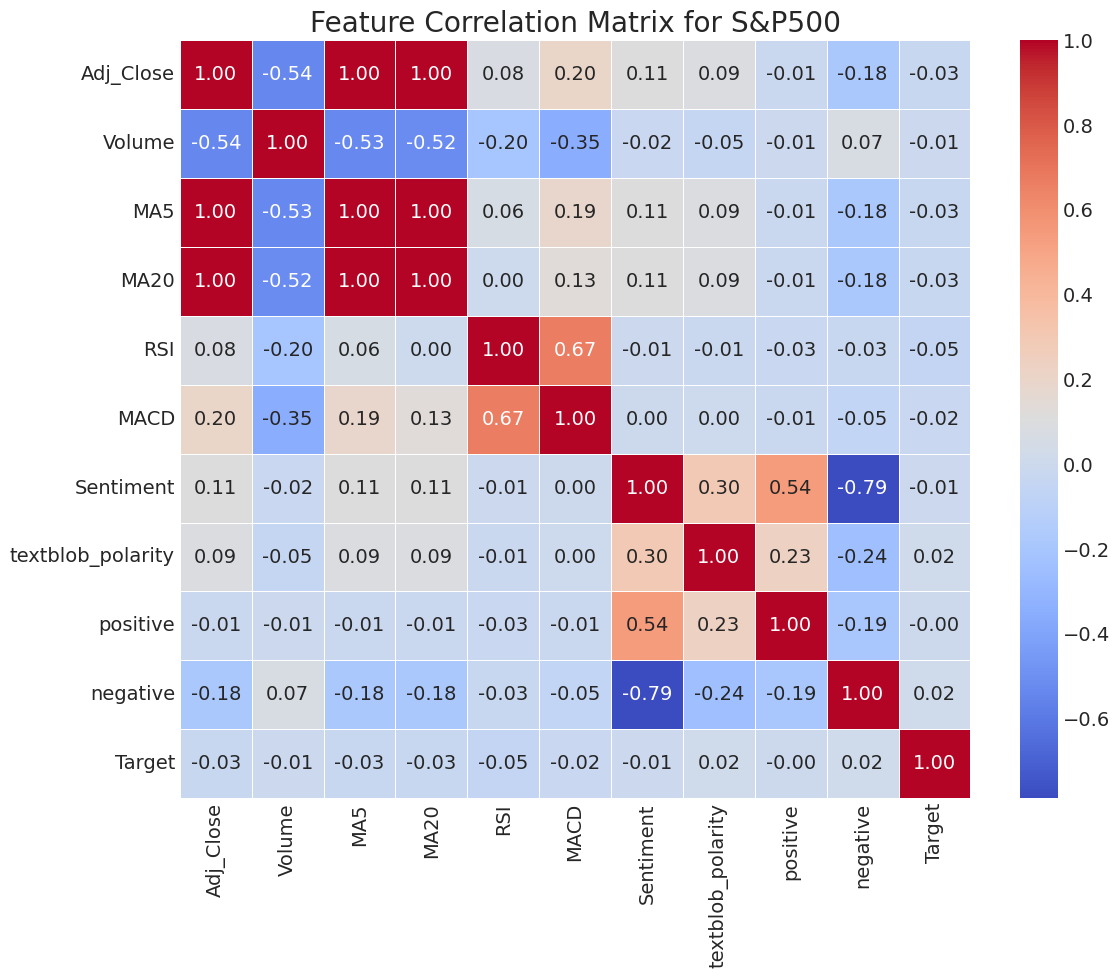


Exploring Apple data:


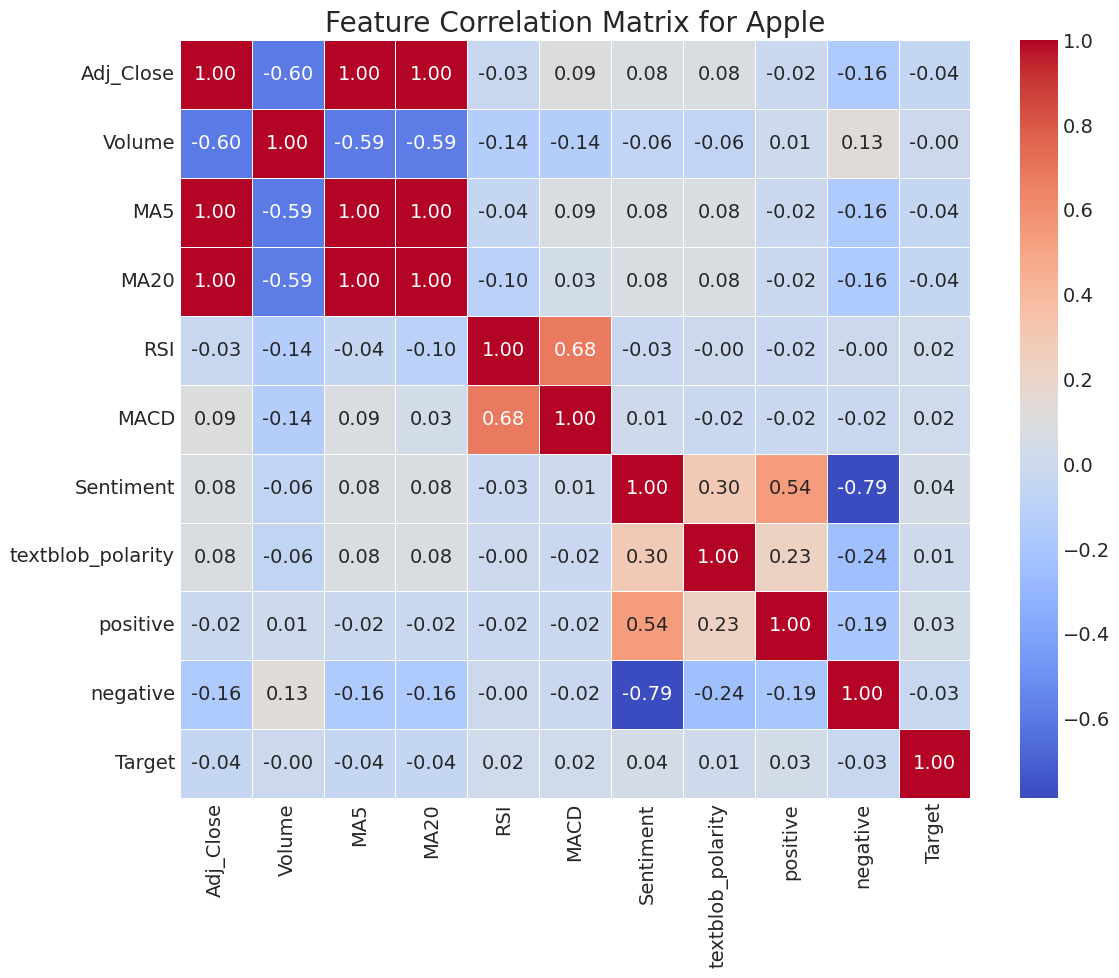


Exploring Microsoft data:


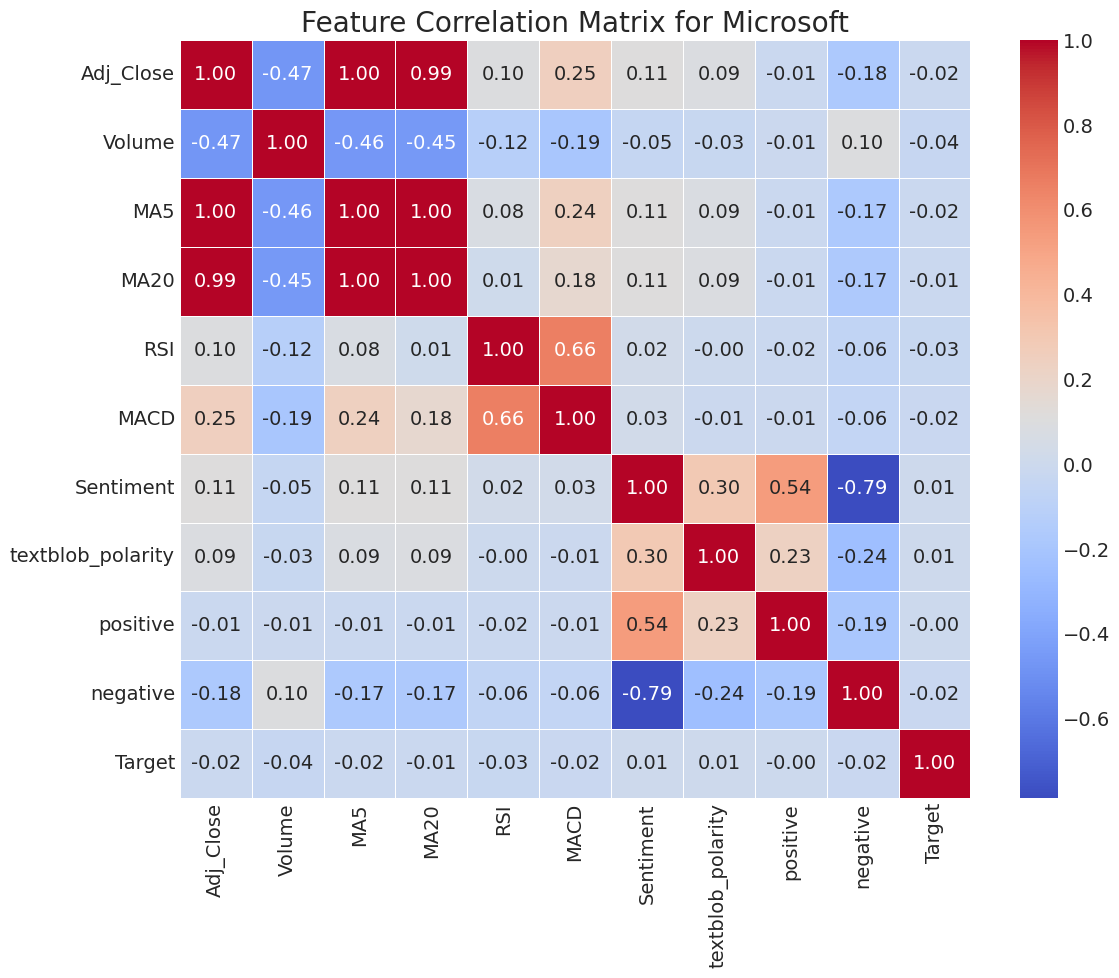

In [10]:
# Create interactive visualization for price, volume, and sentiment
for name, df in datasets.items():
    print(f"\nExploring {name} data:")

    # Create an interactive time series plot with plotly
    fig = make_subplots(rows=3, cols=1,
                        shared_xaxes=True,
                        vertical_spacing=0.05,
                        subplot_titles=('Stock Price vs Moving Averages',
                                        'Trading Volume',
                                        'News Sentiment'))

    # Stock price and MAs
    fig.add_trace(go.Scatter(x=df['Date'], y=df['Adj_Close'],
                            mode='lines', name='Adj Close',
                            line=dict(color='royalblue')), row=1, col=1)

    fig.add_trace(go.Scatter(x=df['Date'], y=df['MA5'],
                            mode='lines', name='5-day MA',
                            line=dict(color='orange')), row=1, col=1)

    fig.add_trace(go.Scatter(x=df['Date'], y=df['MA20'],
                            mode='lines', name='20-day MA',
                            line=dict(color='green')), row=1, col=1)

    # Volume
    fig.add_trace(go.Bar(x=df['Date'], y=df['Volume'],
                        name='Volume', marker_color='darkblue'),
                row=2, col=1)

    # Sentiment
    fig.add_trace(go.Scatter(x=df['Date'], y=df['Sentiment'],
                            mode='lines', name='News Sentiment',
                            line=dict(color='red')), row=3, col=1)

    fig.update_layout(height=800, width=1000,
                    title_text=f'{name} Stock Price, Volume and News Sentiment',
                    showlegend=True)

    fig.show()

    # Correlation heatmap of features
    plt.figure(figsize=(12, 10))
    corr_matrix = df[['Adj_Close', 'Volume', 'MA5', 'MA20', 'RSI', 'MACD',
                    'Sentiment', 'textblob_polarity', 'positive', 'negative', 'Target']].corr()

    sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
    plt.title(f'Feature Correlation Matrix for {name}')
    plt.tight_layout()
    plt.show()

# CRISP-DM 3 – Data Preparation (windowed sequences for DL)

In [11]:
# Helper functions to prepare data for modeling
def create_sequences(df, lookback=10, features=None, target='Target'):
    """Create sequences for deep learning models with specified features"""
    if features is None:
        features = ['Adj_Close', 'Sentiment']

    X, y = [], []
    vals = df[features].values
    labels = df[target].values

    for i in range(len(df) - lookback):
        X.append(vals[i:i+lookback])
        y.append(labels[i+lookback])

    return np.array(X), np.array(y)

# Define feature sets to compare different models
feature_sets = {
    'basic': ['Adj_Close', 'Sentiment'],
    'extended': ['Adj_Close', 'Volume', 'RSI', 'MACD', 'Sentiment', 'textblob_polarity'],
    'full': ['Adj_Close', 'Volume', 'MA5', 'MA20', 'RSI', 'MACD', 'Signal_Line',
             'Price_Change', 'Sentiment', 'positive', 'negative', 'textblob_polarity']
}

lookback = 10
seq_data = {}

for feature_set_name, features in feature_sets.items():
    seq_data[feature_set_name] = {}
    for ticker_name, df in datasets.items():
        X, y = create_sequences(df, lookback, features)
        seq_data[feature_set_name][ticker_name] = (X, y)
        print(f"{ticker_name} with {feature_set_name} features → X: {X.shape}, y: {y.shape}")

S&P500 with basic features → X: (2002, 10, 2), y: (2002,)
Apple with basic features → X: (2002, 10, 2), y: (2002,)
Microsoft with basic features → X: (2002, 10, 2), y: (2002,)
S&P500 with extended features → X: (2002, 10, 6), y: (2002,)
Apple with extended features → X: (2002, 10, 6), y: (2002,)
Microsoft with extended features → X: (2002, 10, 6), y: (2002,)
S&P500 with full features → X: (2002, 10, 12), y: (2002,)
Apple with full features → X: (2002, 10, 12), y: (2002,)
Microsoft with full features → X: (2002, 10, 12), y: (2002,)


In [12]:
# Chronological train/validation/test split
def chrono_split(X, y, train=.7, val=.15):
    """Split data chronologically into train/val/test sets"""
    n = len(X)
    t = int(n*train)
    v = int(n*(train+val))
    return X[:t], y[:t], X[t:v], y[t:v], X[v:], y[v:]

# Prepare splits for each feature set and ticker
splits = {}
for feature_set in feature_sets.keys():
    splits[feature_set] = {}
    for ticker, (X, y) in seq_data[feature_set].items():
        splits[feature_set][ticker] = chrono_split(X, y)

# CRISP-DM 4 – Modelling (Baseline ML – GradientBoostingClassifier)

S&P500 - Baseline Acc=0.561  F1=0.563  ROC=0.571


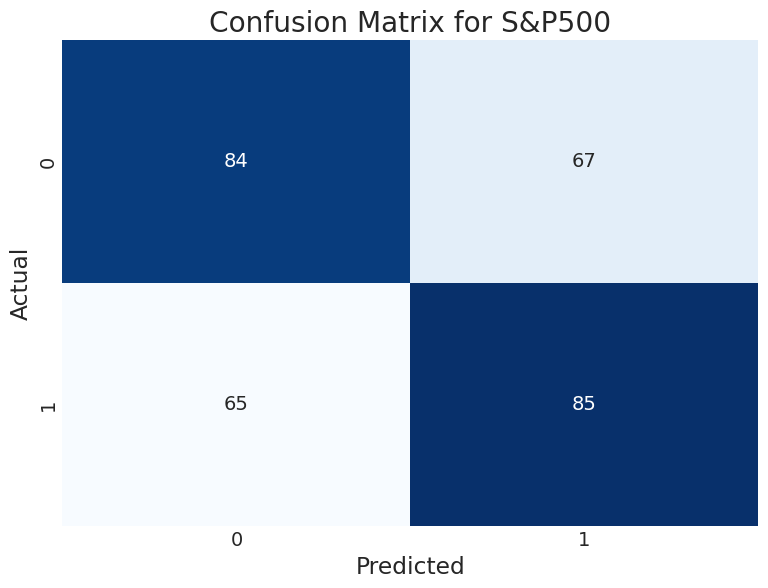

Apple - Baseline Acc=0.468  F1=0.527  ROC=0.509


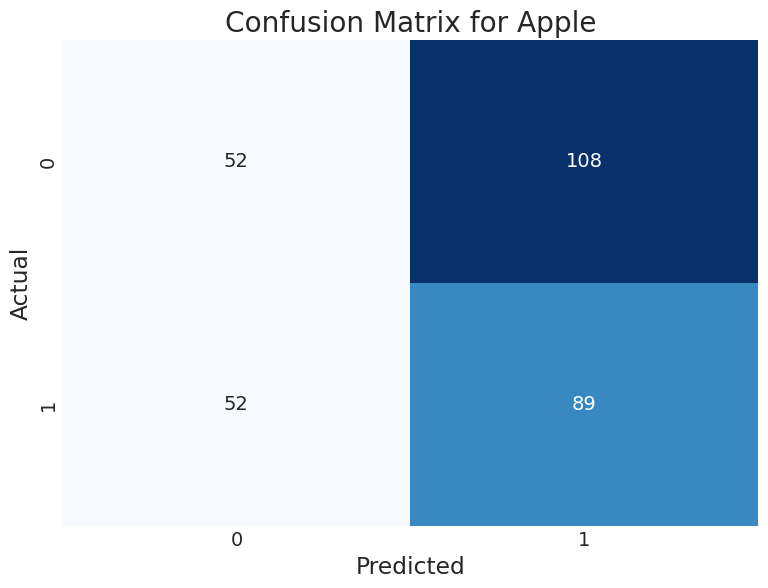

Microsoft - Baseline Acc=0.502  F1=0.543  ROC=0.514


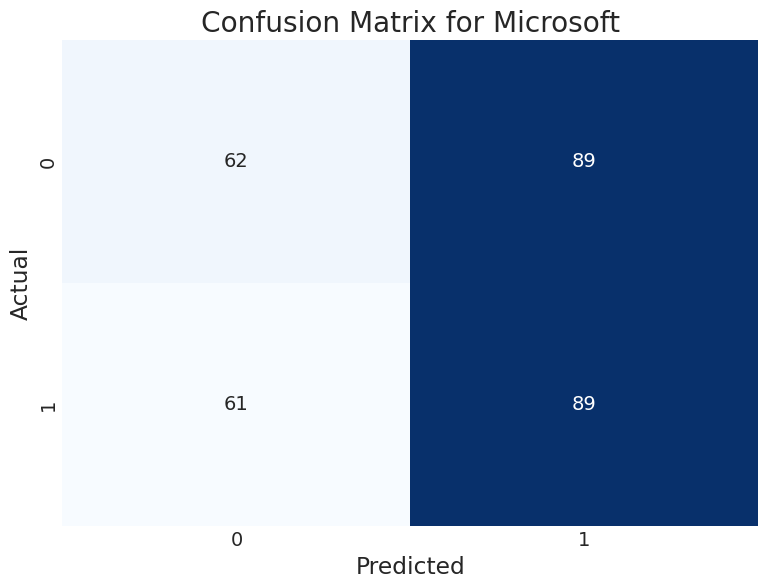

In [13]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report
from sklearn.metrics import confusion_matrix, precision_recall_curve, roc_curve

# Function to flatten the windowed data for traditional ML models
def prepare_ml_features(df, lookback=10, features=None):
    if features is None:
        features = ['Adj_Close', 'Sentiment']

    flat_features = []
    labels = df['Target'].values[lookback:]

    for i in range(len(df) - lookback):
        window = df[features].values[i:i+lookback].flatten()
        flat_features.append(window)

    return np.array(flat_features), labels

ml_results = {}

for name, df in datasets.items():
    # Use the full feature set for baseline model
    features = feature_sets['full']
    features_flat, labels = prepare_ml_features(df, lookback, features)
    X_train, y_train, X_val, y_val, X_test, y_test = chrono_split(features_flat, labels)

    # Combine train and validation for final model training
    X_train_full = np.concatenate([X_train, X_val])
    y_train_full = np.concatenate([y_train, y_val])

    # Train model with hyperparameters
    gb = GradientBoostingClassifier(n_estimators=300, learning_rate=0.05,
                                    max_depth=4, random_state=RANDOM_SEED)
    gb.fit(X_train_full, y_train_full)

    # Make predictions
    preds = gb.predict(X_test)
    preds_proba = gb.predict_proba(X_test)[:, 1]

    # Calculate metrics
    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds)
    roc = roc_auc_score(y_test, preds_proba)

    ml_results[name] = {
        'model': gb,
        'acc': acc,
        'f1': f1,
        'roc': roc,
        'y_test': y_test,
        'y_pred': preds,
        'y_pred_proba': preds_proba,
        'features': features
    }

    print(f"{name} - Baseline Acc={acc:.3f}  F1={f1:.3f}  ROC={roc:.3f}")

    # Plot confusion matrix
    plt.figure(figsize=(8, 6))
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title(f'Confusion Matrix for {name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

# CRISP-DM 4 – Modelling (LSTM)


Training LSTM models with diverse hyperparameters...

Training LSTM for S&P500...
Testing 4 diverse parameter combinations
Testing parameters: {'units': 64, 'dropout': 0.3, 'lr': 0.001, 'num_layers': 1, 'dense_units': 32, 'name': 'Baseline'}
Epoch 1/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.5265 - loss: 0.7061 - val_accuracy: 0.5533 - val_loss: 0.6871 - learning_rate: 0.0010
Epoch 2/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.5533 - loss: 0.6894 - val_accuracy: 0.5533 - val_loss: 0.6886 - learning_rate: 0.0010
Epoch 3/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5488 - loss: 0.6943 - val_accuracy: 0.5633 - val_loss: 0.6884 - learning_rate: 0.0010
Epoch 4/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.5191 - loss: 0.6915 - val_accuracy: 0.5667 - val_loss: 0.6868 - learning_rate: 5.0000e-04
Epoch 5/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5505 - loss: 0.6852 - val_accuracy: 0.5467 - val_loss: 0.6887 - learning_rate: 5.0000e-0

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 10, 128)        │        72,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 128)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 636,293 (2.43 MB)

 Trainable params: 212,097 (828.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 424,196 (1.62 MB)

S&P500 – LSTM Best Model Test Accuracy: 0.508, F1: 0.661, ROC AUC: 0.497


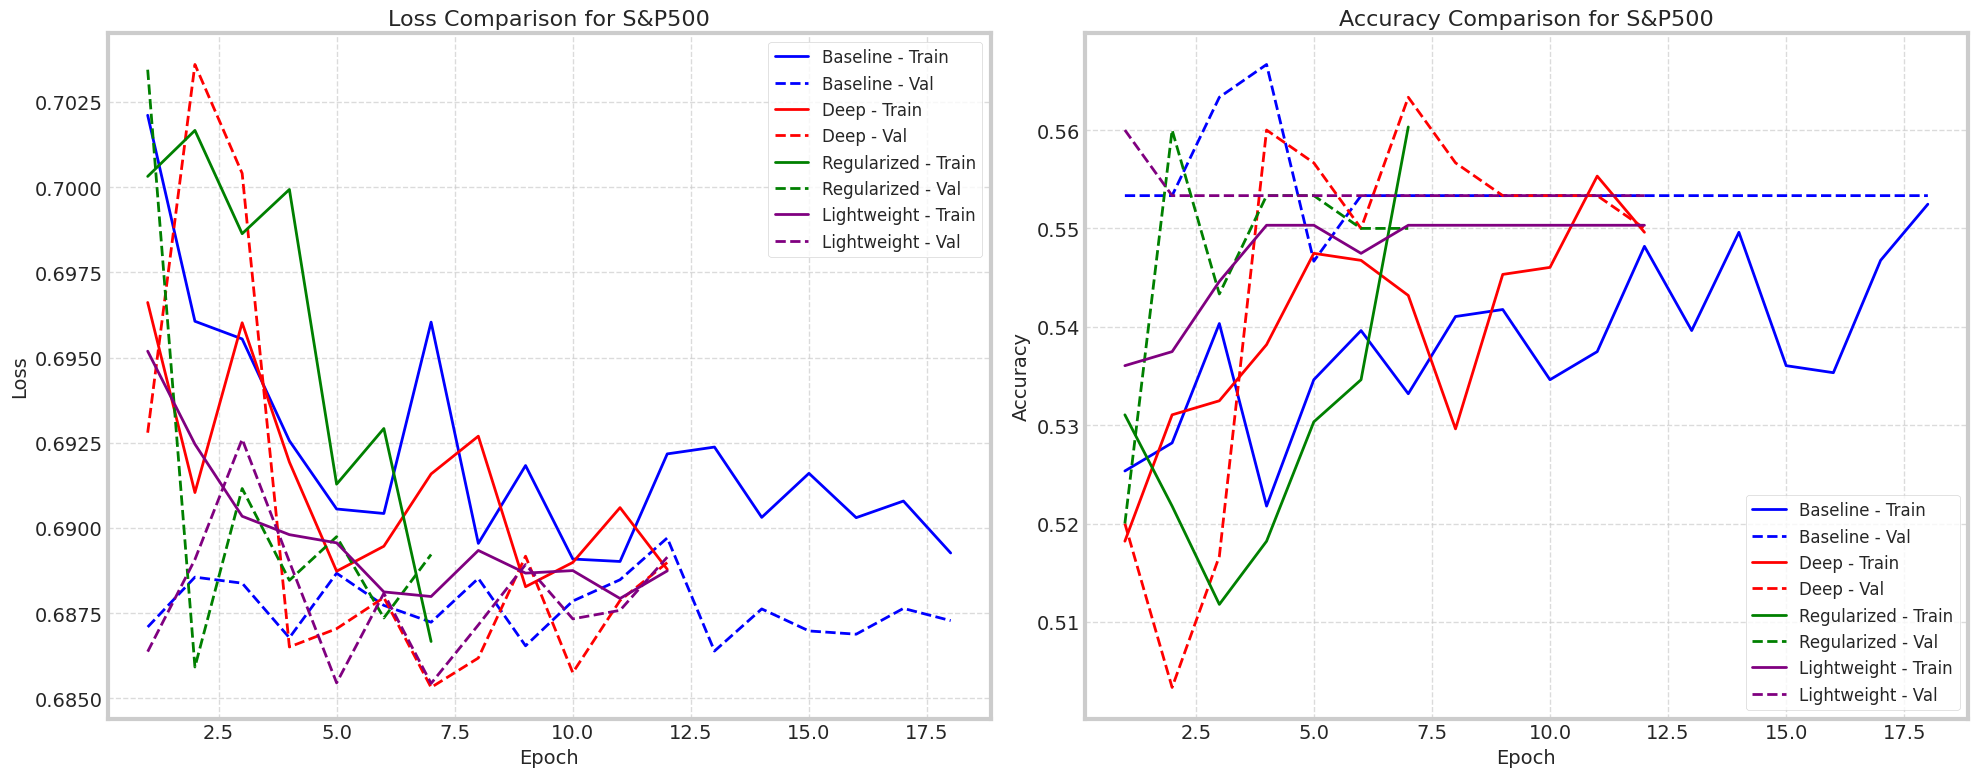


Training LSTM for Apple...
Testing 4 diverse parameter combinations
Testing parameters: {'units': 64, 'dropout': 0.3, 'lr': 0.001, 'num_layers': 1, 'dense_units': 32, 'name': 'Baseline'}
Epoch 1/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.5068 - loss: 0.7051 - val_accuracy: 0.5000 - val_loss: 0.6932 - learning_rate: 0.0010
Epoch 2/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5233 - loss: 0.6928 - val_accuracy: 0.4733 - val_loss: 0.6946 - learning_rate: 0.0010
Epoch 3/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4921 - loss: 0.6997 - val_accuracy: 0.4833 - val_loss: 0.6991 - learning_rate: 0.0010
Epoch 4/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5187 - loss: 0.6924 - val_accuracy: 0.5167 - val_loss: 0.6909 - learning_rate: 5.0000e-04
Epoch 5/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5444 - loss: 0.6896 - val_accuracy: 0.5433 - val_loss: 0.6893 - learning_rate: 5.0000e-04
Epoch 6/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - a

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_5 (LSTM)                   │ (None, 64)             │        19,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 65,477 (255.77 KB)

 Trainable params: 21,825 (85.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 43,652 (170.52 KB)

Apple – LSTM Best Model Test Accuracy: 0.432, F1: 0.597, ROC AUC: 0.543


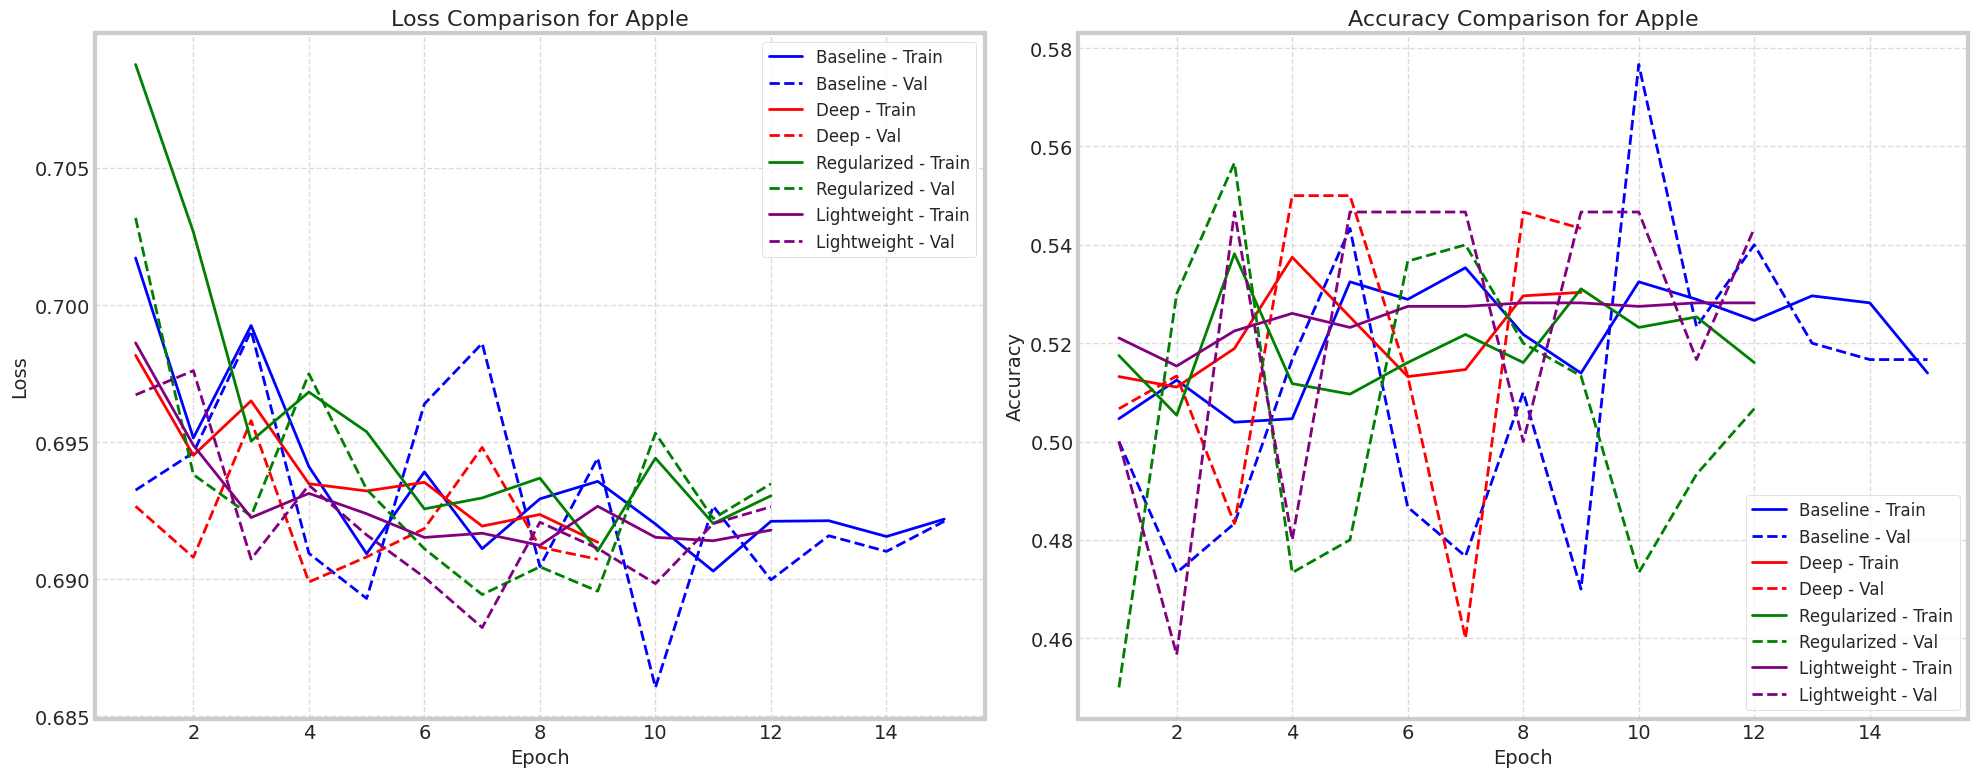


Training LSTM for Microsoft...
Testing 4 diverse parameter combinations
Testing parameters: {'units': 64, 'dropout': 0.3, 'lr': 0.001, 'num_layers': 1, 'dense_units': 32, 'name': 'Baseline'}
Epoch 1/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.4808 - loss: 0.7080 - val_accuracy: 0.4933 - val_loss: 0.6920 - learning_rate: 0.0010
Epoch 2/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.4936 - loss: 0.7027 - val_accuracy: 0.5033 - val_loss: 0.6921 - learning_rate: 0.0010
Epoch 3/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.4862 - loss: 0.6982 - val_accuracy: 0.4900 - val_loss: 0.6960 - learning_rate: 0.0010
Epoch 4/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.4906 - loss: 0.6979 - val_accuracy: 0.5133 - val_loss: 0.6954 - learning_rate: 5.0000e-04
Epoch 5/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.5036 - loss: 0.6973 - val_accuracy: 0.5233 - val_loss: 0.6922 - learning_rate: 5.0000e-04
Epoch 6/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_13 (LSTM)                  │ (None, 64)             │        19,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 65,477 (255.77 KB)

 Trainable params: 21,825 (85.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 43,652 (170.52 KB)

Microsoft - Best threshold for final model: 0.20 with F1 = 0.665
Microsoft – LSTM Best Model Test Accuracy: 0.495, F1: 0.665, ROC AUC: 0.505


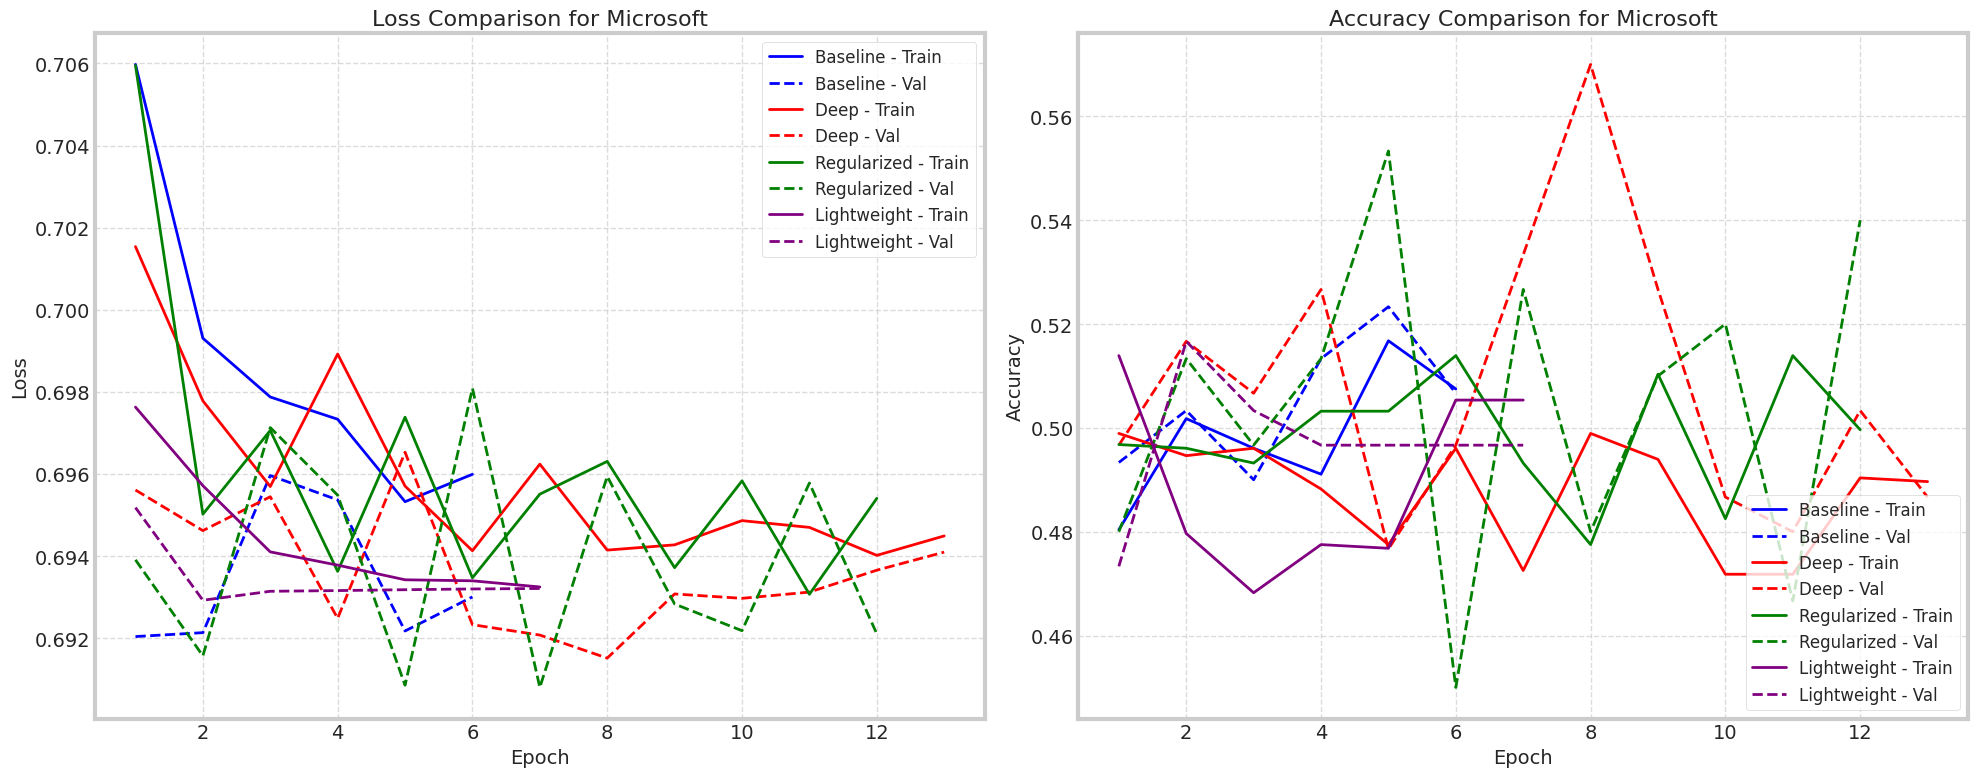

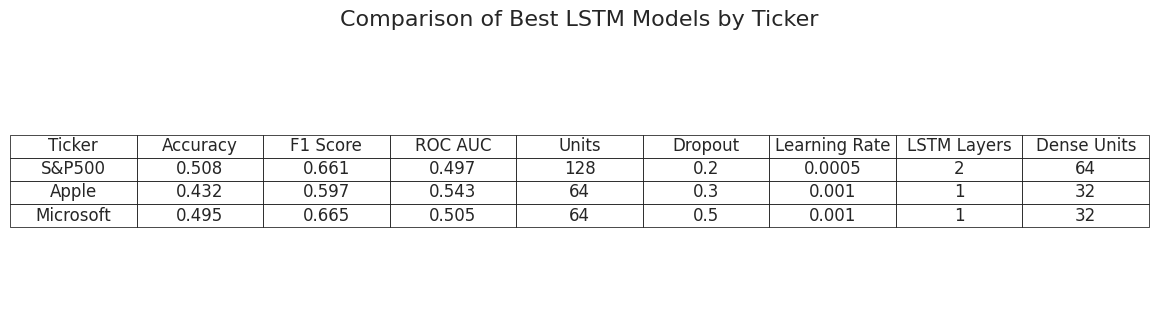

In [14]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, optimizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, roc_auc_score
import numpy as np
import pandas as pd

tf.random.set_seed(RANDOM_SEED)

def build_lstm(input_shape, units=64, dropout=0.2, lr=0.001, num_layers=1, dense_units=32):
    """Build LSTM model with given hyperparameters"""
    model = models.Sequential()
    model.add(layers.Input(shape=input_shape))
    # Add LSTM layers
    for i in range(num_layers):
        return_sequences = i < num_layers - 1
        if i == 0:
            model.add(layers.LSTM(units, return_sequences=return_sequences, dropout=dropout))
        else:
            model.add(layers.LSTM(units, return_sequences=return_sequences, dropout=dropout))
    model.add(layers.Dense(dense_units, activation='relu'))
    model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation='sigmoid'))
    optimizer = optimizers.Adam(learning_rate=lr)
    model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])
    return model

# Create diverse but limited parameter combinations
def create_diverse_params(max_combinations=4):
    # Create 4 diverse parameter combinations
    param_combinations = [
        # Baseline configuration
        {
            'units': 64,
            'dropout': 0.3,
            'lr': 0.001,
            'num_layers': 1,
            'dense_units': 32,
            'name': 'Baseline'  # For plotting
        },
        # Deeper network
        {
            'units': 128,
            'dropout': 0.2,
            'lr': 0.0005,
            'num_layers': 2,
            'dense_units': 64,
            'name': 'Deep'  # For plotting
        },
        # Regularized
        {
            'units': 64,
            'dropout': 0.5,
            'lr': 0.001,
            'num_layers': 1,
            'dense_units': 32,
            'name': 'Regularized'  # For plotting
        },
        # Lightweight
        {
            'units': 32,
            'dropout': 0.2,
            'lr': 0.01,
            'num_layers': 1,
            'dense_units': 16,
            'name': 'Lightweight'  # For plotting
        }
    ]
    return param_combinations

dl_results = {}
all_training_results = {}  # Store all results for visualization
EPOCHS = 20
BATCH_SIZE = 32
PATIENCE = 5

print("\nTraining LSTM models with diverse hyperparameters...")
for ticker, (X, y) in seq_data['full'].items():
    print(f"\nTraining LSTM for {ticker}...")
    X_tr, y_tr, X_val, y_val, X_te, y_te = splits['full'][ticker]
    # Define callbacks for training
    callbacks_list = [
        EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=0.00001)
    ]
    # Generate parameter combinations
    param_combinations = create_diverse_params(max_combinations=4)
    print(f"Testing {len(param_combinations)} diverse parameter combinations")
    # Initialize tracking
    best_val_loss = float('inf')
    best_params = None
    best_model = None
    best_history = None
    # Store all training histories
    ticker_results = {
        'loss_data': [],
        'acc_data': [],
        'val_loss_data': [],
        'val_acc_data': [],
        'param_names': []
    }
    # Colors for plotting
    colors = ['blue', 'red', 'green', 'purple']
    # Limited hyperparameter search
    for i, params in enumerate(param_combinations):
        print(f"Testing parameters: {params}")
        # Build model with current parameters
        model = build_lstm(
            X_tr.shape[1:],
            units=params['units'],
            dropout=params['dropout'],
            lr=params['lr'],
            num_layers=params['num_layers'],
            dense_units=params['dense_units']
        )
        # Train the model
        history = model.fit(
            X_tr, y_tr,
            validation_data=(X_val, y_val),
            epochs=EPOCHS,
            batch_size=BATCH_SIZE,
            callbacks=callbacks_list,
            verbose=1  # Set to 1 to see progress for each model
        )
        # Check if this model is better
        val_loss = min(history.history['val_loss'])
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_params = {k: v for k, v in params.items() if k != 'name'}
            best_model = model
            best_history = history
        # Store training history for visualization
        ticker_results['loss_data'].append((history.history['loss'], colors[i]))
        ticker_results['val_loss_data'].append((history.history['val_loss'], colors[i]))
        ticker_results['acc_data'].append((history.history['accuracy'], colors[i]))
        ticker_results['val_acc_data'].append((history.history['val_accuracy'], colors[i]))
        ticker_results['param_names'].append(params['name'])

        # MODIFICATION 1: Store test metrics for this configuration with adaptive threshold
        test_loss, test_acc = model.evaluate(X_te, y_te, verbose=0)
        y_pred_proba = model.predict(X_te, verbose=0).flatten()

        # Adaptive threshold specifically for Microsoft
        if ticker == "Microsoft":
            best_f1 = 0
            best_threshold = 0.5
            # Try a range of thresholds to find optimal value
            for threshold in np.arange(0.2, 0.8, 0.05):
                tmp_pred = (y_pred_proba > threshold).astype(int)
                tmp_f1 = f1_score(y_te, tmp_pred)
                if tmp_f1 > best_f1:
                    best_f1 = tmp_f1
                    best_threshold = threshold

            y_pred = (y_pred_proba > best_threshold).astype(int)
            f1 = best_f1
            roc = roc_auc_score(y_te, y_pred_proba)
            print(f"{ticker} - {params['name']} - Test Accuracy: {test_acc:.3f}, F1: {f1:.3f} (threshold={best_threshold:.2f}), ROC AUC: {roc:.3f}")
        else:
            # Original code for other tickers
            y_pred = (y_pred_proba > 0.5).astype(int)
            f1 = f1_score(y_te, y_pred)
            roc = roc_auc_score(y_te, y_pred_proba)
            print(f"{ticker} - {params['name']} - Test Accuracy: {test_acc:.3f}, F1: {f1:.3f}, ROC AUC: {roc:.3f}")

    # Save all training results
    all_training_results[ticker] = ticker_results
    # Display best model summary
    print(f"\nBest parameters for {ticker}: {best_params}")
    best_model.summary()

    # MODIFICATION 2: Evaluate best model on test set with adaptive threshold
    test_loss, test_acc = best_model.evaluate(X_te, y_te, verbose=0)
    y_pred_proba = best_model.predict(X_te, verbose=0).flatten()

    # Adaptive threshold specifically for Microsoft's best model
    if ticker == "Microsoft":
        best_f1 = 0
        best_threshold = 0.5
        # Use a finer-grained search for the best model
        for threshold in np.arange(0.2, 0.8, 0.02):
            tmp_pred = (y_pred_proba > threshold).astype(int)
            tmp_f1 = f1_score(y_te, tmp_pred)
            if tmp_f1 > best_f1:
                best_f1 = tmp_f1
                best_threshold = threshold

        print(f"Microsoft - Best threshold for final model: {best_threshold:.2f} with F1 = {best_f1:.3f}")
        y_pred = (y_pred_proba > best_threshold).astype(int)
        f1 = best_f1
    else:
        # Original code for other tickers
        y_pred = (y_pred_proba > 0.5).astype(int)
        f1 = f1_score(y_te, y_pred)

    roc = roc_auc_score(y_te, y_pred_proba)

    dl_results[ticker] = {
        'model': best_model,
        'history': best_history,
        'params': best_params,
        'acc': test_acc,
        'f1': f1,
        'roc': roc,
        'y_test': y_te,
        'y_pred': y_pred,
        'y_pred_proba': y_pred_proba
    }
    dl_results[ticker]['LSTM'] = dl_results[ticker]
    print(f"{ticker} – LSTM Best Model Test Accuracy: {test_acc:.3f}, F1: {f1:.3f}, ROC AUC: {roc:.3f}")

    # Plot all training results for this ticker
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))
    # Plot loss
    ax1.set_title(f'Loss Comparison for {ticker}', fontsize=16)
    ax1.set_xlabel('Epoch', fontsize=14)
    ax1.set_ylabel('Loss', fontsize=14)
    for i, ((loss_data, color), (val_loss_data, val_color), param_name) in enumerate(zip(
        ticker_results['loss_data'],
        ticker_results['val_loss_data'],
        ticker_results['param_names']
    )):
        epochs = range(1, len(loss_data) + 1)
        ax1.plot(epochs, loss_data, color=color, linestyle='-',
                 linewidth=2, label=f'{param_name} - Train')
        ax1.plot(epochs, val_loss_data, color=color, linestyle='--',
                 linewidth=2, label=f'{param_name} - Val')
    ax1.legend(loc='upper right', fontsize=12)
    ax1.grid(True, linestyle='--', alpha=0.7)

    # Plot accuracy
    ax2.set_title(f'Accuracy Comparison for {ticker}', fontsize=16)
    ax2.set_xlabel('Epoch', fontsize=14)
    ax2.set_ylabel('Accuracy', fontsize=14)
    for i, ((acc_data, color), (val_acc_data, val_color), param_name) in enumerate(zip(
        ticker_results['acc_data'],
        ticker_results['val_acc_data'],
        ticker_results['param_names']
    )):
        epochs = range(1, len(acc_data) + 1)
        ax2.plot(epochs, acc_data, color=color, linestyle='-',
                 linewidth=2, label=f'{param_name} - Train')
        ax2.plot(epochs, val_acc_data, color=color, linestyle='--',
                 linewidth=2, label=f'{param_name} - Val')
    ax2.legend(loc='lower right', fontsize=12)
    ax2.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

# Create comparison table of best models for each ticker
def create_comparison_table(results):
    data = []
    for ticker, info in results.items():
        data.append({
            'Ticker': ticker,
            'Accuracy': f"{info['acc']:.3f}",
            'F1 Score': f"{info['f1']:.3f}",
            'ROC AUC': f"{info['roc']:.3f}",
            'Units': info['params']['units'],
            'Dropout': info['params']['dropout'],
            'Learning Rate': info['params']['lr'],
            'LSTM Layers': info['params']['num_layers'],
            'Dense Units': info['params']['dense_units']
        })
    df = pd.DataFrame(data)
    # Plot comparison as a table
    fig, ax = plt.subplots(figsize=(12, len(results) * 0.8 + 1))
    ax.axis('off')
    ax.axis('tight')
    table = ax.table(
        cellText=df.values,
        colLabels=df.columns,
        loc='center',
        cellLoc='center'
    )
    table.auto_set_font_size(False)
    table.set_fontsize(12)
    table.scale(1.2, 1.5)
    plt.title('Comparison of Best LSTM Models by Ticker', fontsize=16, pad=20)
    plt.tight_layout()
    plt.show()

# Display comparison table
create_comparison_table(dl_results)

# CRISP-DM 4 – Modelling (1-D CNN) and CNN-LSTM


Training CNN for S&P500 with 4 parameter combinations
Testing parameters: CNN-Baseline


Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 8, 64)          │         2,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 4, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 4, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 32)             │         8,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,625 (41.50 KB)

 Trainable params: 10,625 (41.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 7s 72ms/step - accuracy: 0.4945 - loss: 93.2343 - val_accuracy: 0.4467 - val_loss: 0.9525 - learning_rate: 0.0010
Epoch 2/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.5270 - loss: 6.3186 - val_accuracy: 0.5533 - val_loss: 0.6930 - learning_rate: 0.0010
Epoch 3/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5567 - loss: 1.2004 - val_accuracy: 0.5533 - val_loss: 0.6923 - learning_rate: 0.0010
Epoch 4/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5615 - loss: 0.9881 - val_accuracy: 0.5533 - val_loss: 0.6915 - learning_rate: 0.0010
Epoch 5/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5682 - loss: 0.8258 - val_accuracy: 0.5533 - val_loss: 0.6909 - learning_rate: 0.0010
Epoch 6/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5659 - loss: 0.8230 - val_accuracy: 0.5533 - val_loss: 0.6903 - learning_rate: 0.0010
Epoch 7/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5658 - loss: 0.7524 - val_accuracy

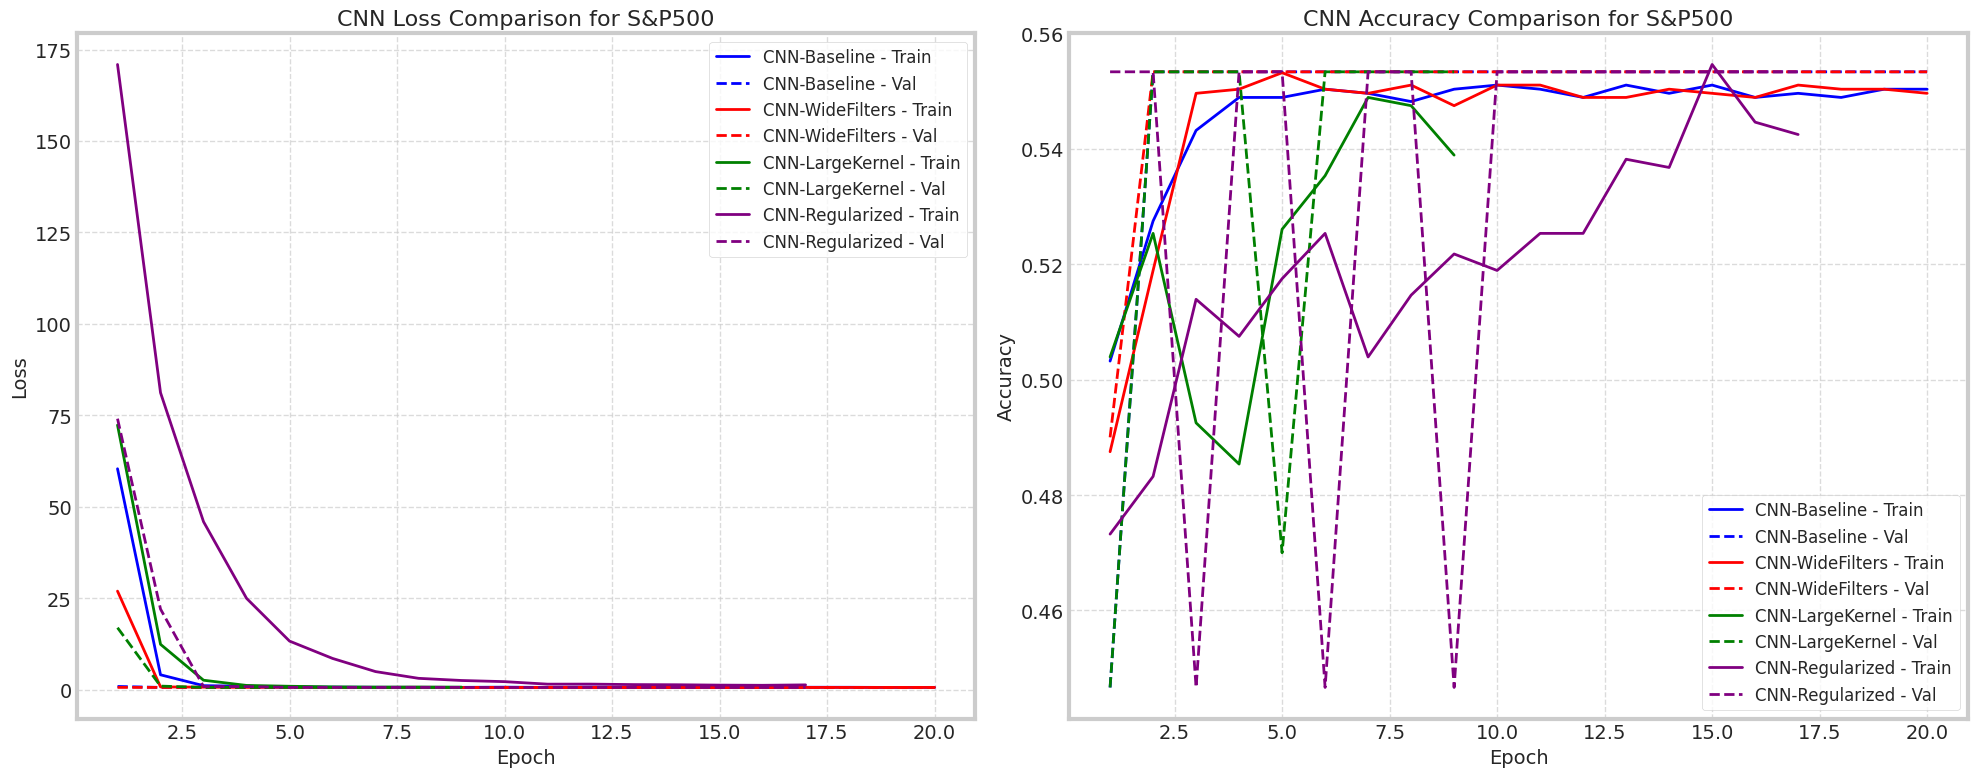

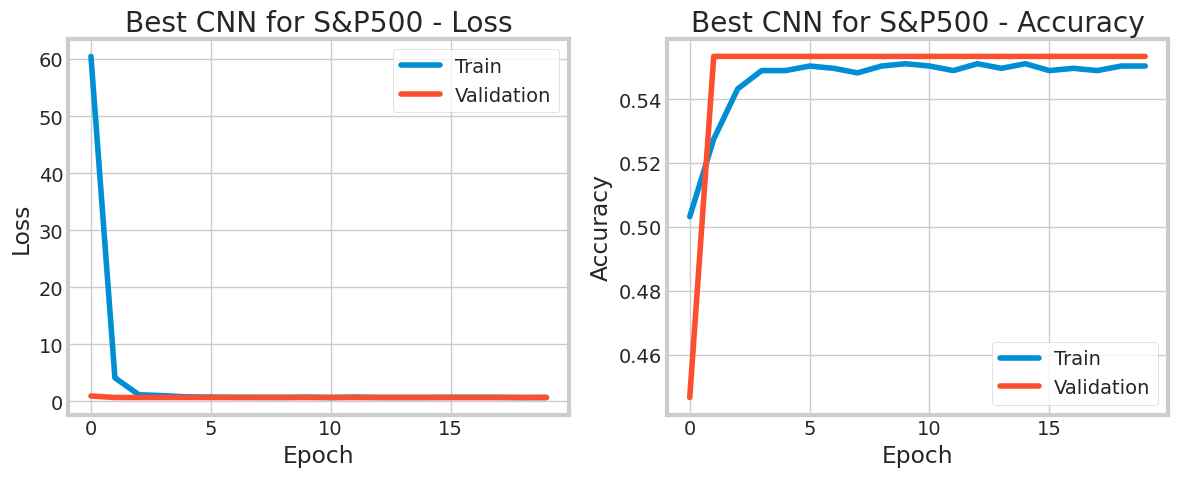


Training CNN-LSTM for S&P500 with 4 parameter combinations
Testing parameters: CNNLSTM-Baseline


Model: "functional_55"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_16 (InputLayer)     │ (None, 10, 12)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 8, 64)          │         2,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_4 (MaxPooling1D)  │ (None, 4, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 4, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_15 (LSTM)                  │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_21 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_22 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 37,505 (146.50 KB)

 Trainable params: 37,505 (146.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.4878 - loss: 0.7560 - val_accuracy: 0.5533 - val_loss: 0.6876 - learning_rate: 0.0010
Epoch 2/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5083 - loss: 0.7209 - val_accuracy: 0.5533 - val_loss: 0.6876 - learning_rate: 0.0010
Epoch 3/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.5259 - loss: 0.7071 - val_accuracy: 0.5533 - val_loss: 0.6882 - learning_rate: 0.0010
Epoch 4/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.5301 - loss: 0.6966 - val_accuracy: 0.5533 - val_loss: 0.6893 - learning_rate: 5.0000e-04
Epoch 5/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5163 - loss: 0.7023 - val_accuracy: 0.5533 - val_loss: 0.6881 - learning_rate: 5.0000e-04
Epoch 6/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5236 - loss: 0.6925 - val_accuracy: 0.5533 - val_loss: 0.6880 - learning_rate: 2.5000e-04
Epoch 7/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.5145 - loss: 0.7026 - v

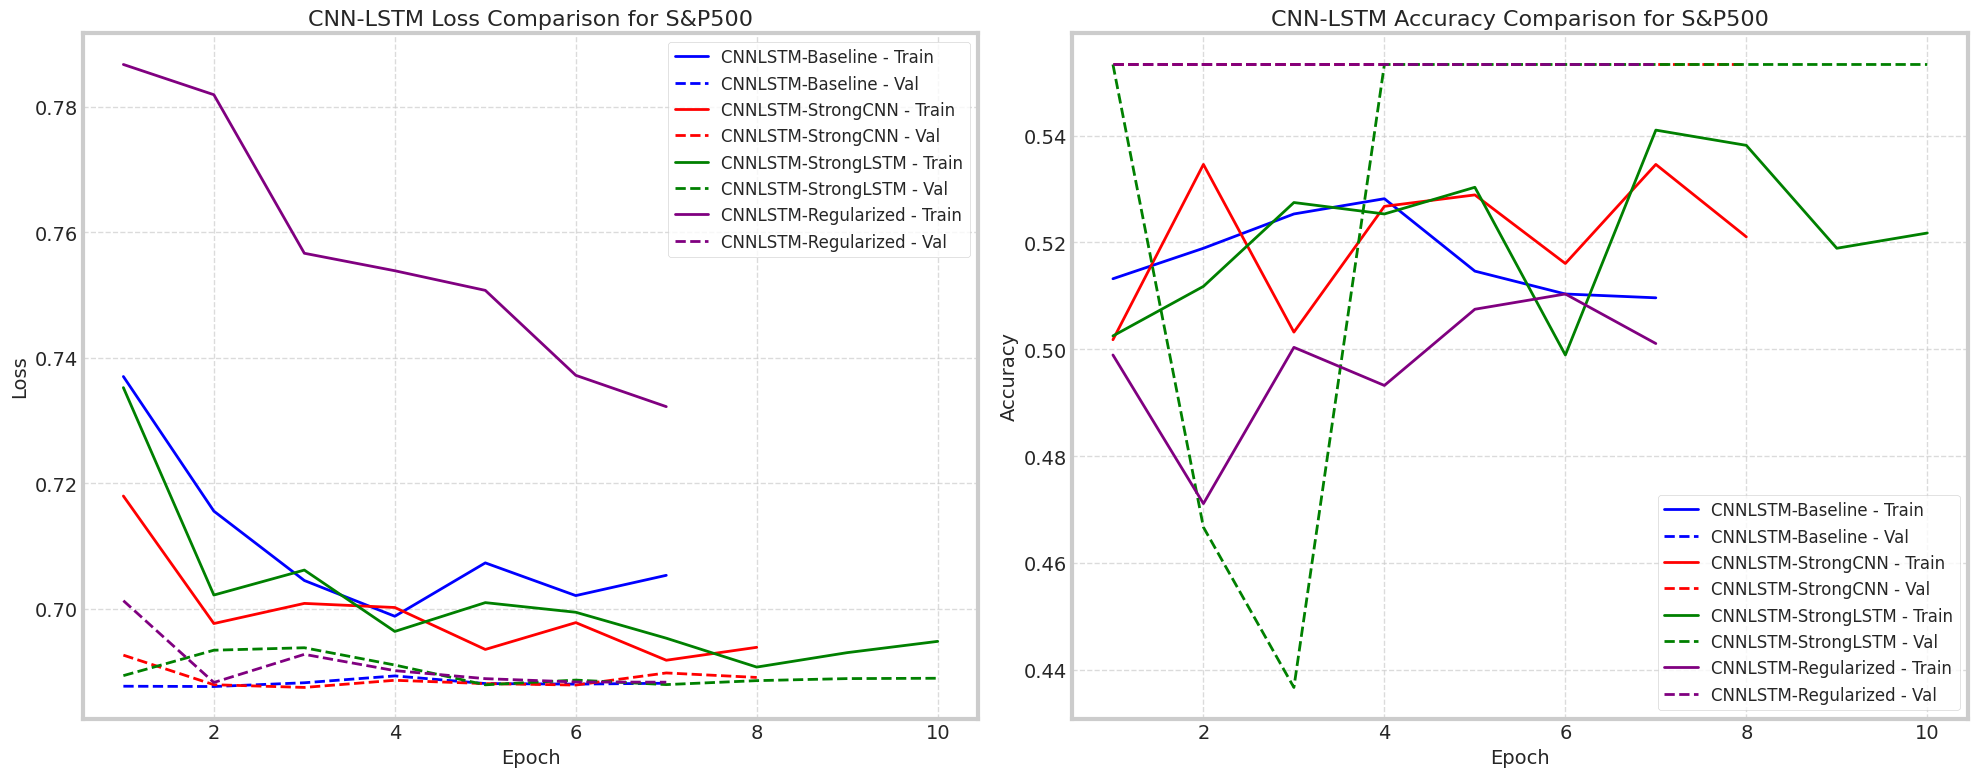

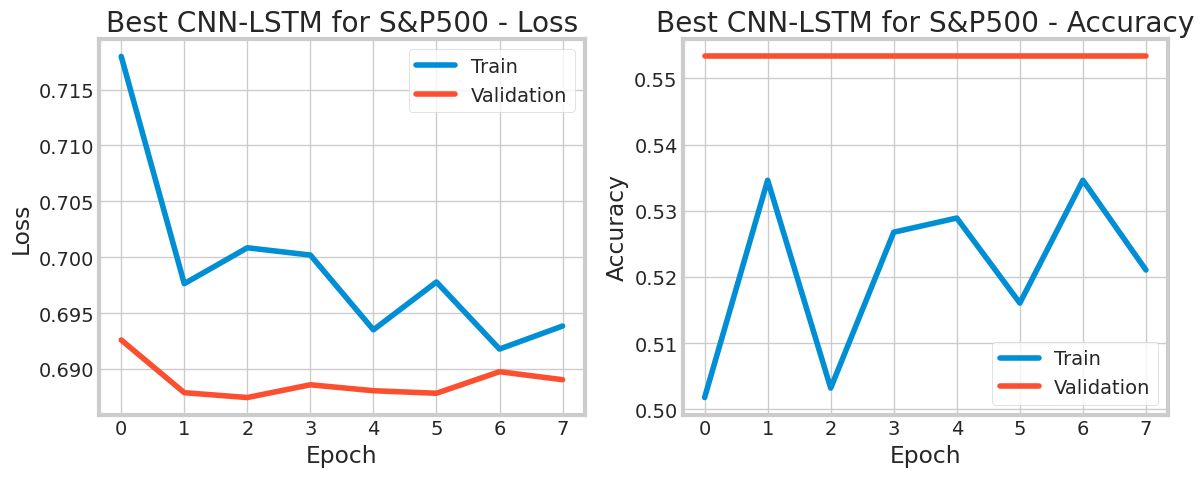


Training CNN for Apple with 4 parameter combinations
Testing parameters: CNN-Baseline


Model: "sequential_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_8 (Conv1D)               │ (None, 8, 64)          │         2,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_8 (MaxPooling1D)  │ (None, 4, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_32 (Dropout)            │ (None, 4, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_40 (Dense)                │ (None, 32)             │         8,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_33 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_41 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,625 (41.50 KB)

 Trainable params: 10,625 (41.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 4s 49ms/step - accuracy: 0.5307 - loss: 1.1983 - val_accuracy: 0.4867 - val_loss: 0.6940 - learning_rate: 0.0010
Epoch 2/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.5178 - loss: 0.7544 - val_accuracy: 0.5467 - val_loss: 0.6900 - learning_rate: 0.0010
Epoch 3/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5107 - loss: 0.7049 - val_accuracy: 0.5467 - val_loss: 0.6909 - learning_rate: 0.0010
Epoch 4/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5287 - loss: 0.6926 - val_accuracy: 0.5467 - val_loss: 0.6926 - learning_rate: 0.0010
Epoch 5/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5116 - loss: 0.6964 - val_accuracy: 0.5467 - val_loss: 0.6925 - learning_rate: 5.0000e-04
Epoch 6/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5317 - loss: 0.6932 - val_accuracy: 0.5467 - val_loss: 0.6924 - learning_rate: 5.0000e-04
Epoch 7/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5343 - loss: 0.6935 - val_a

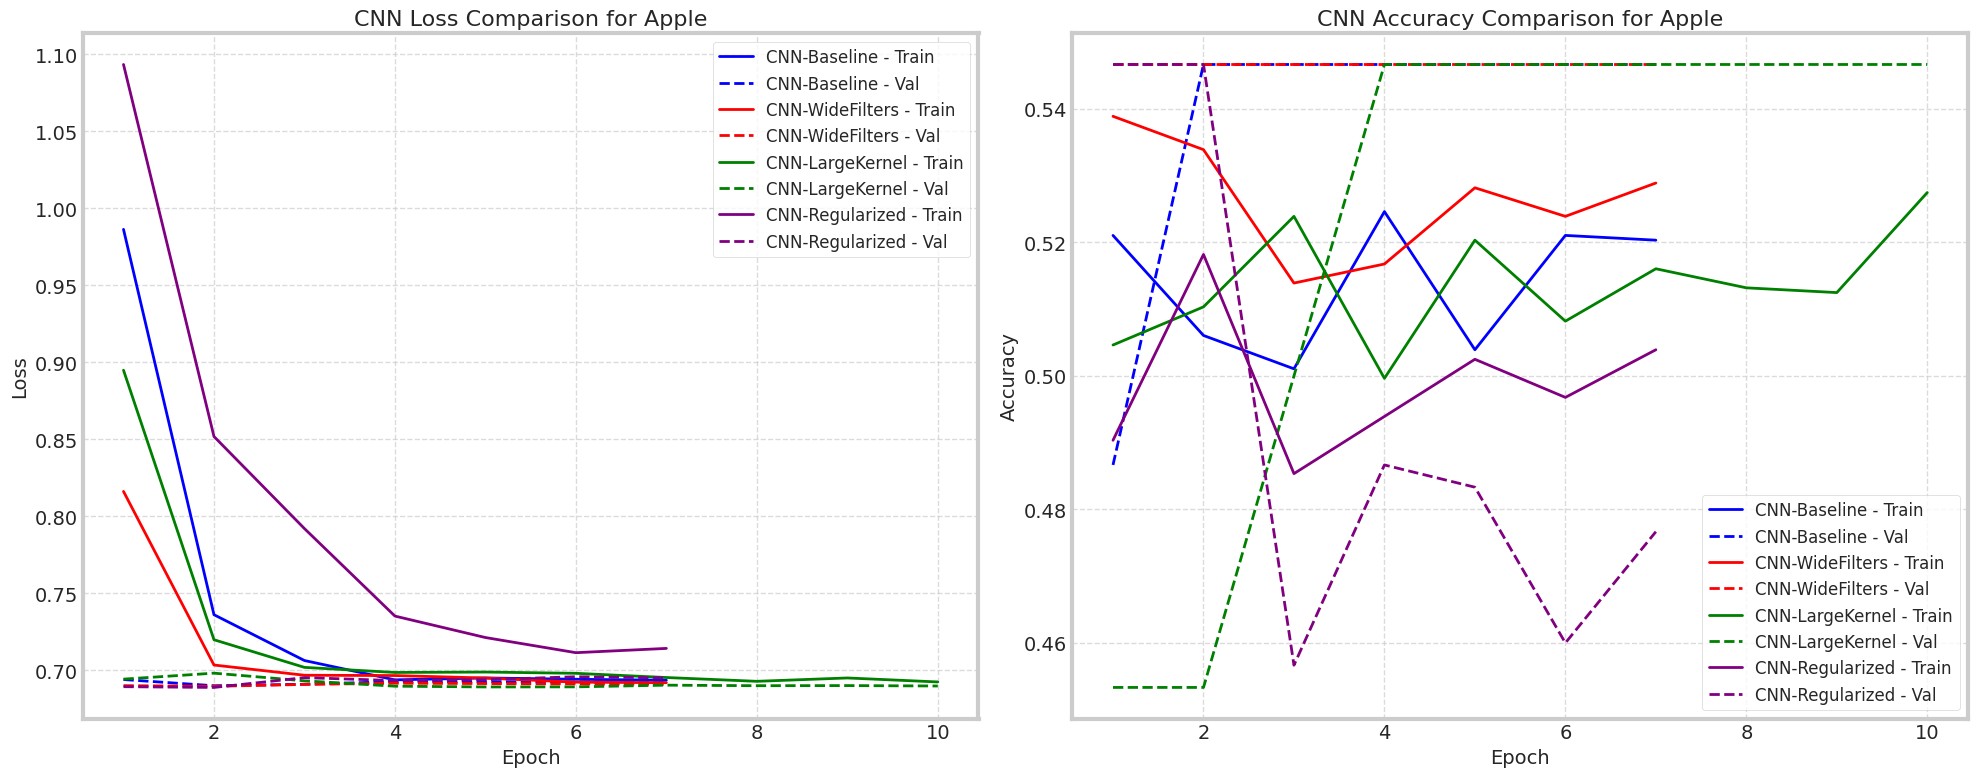

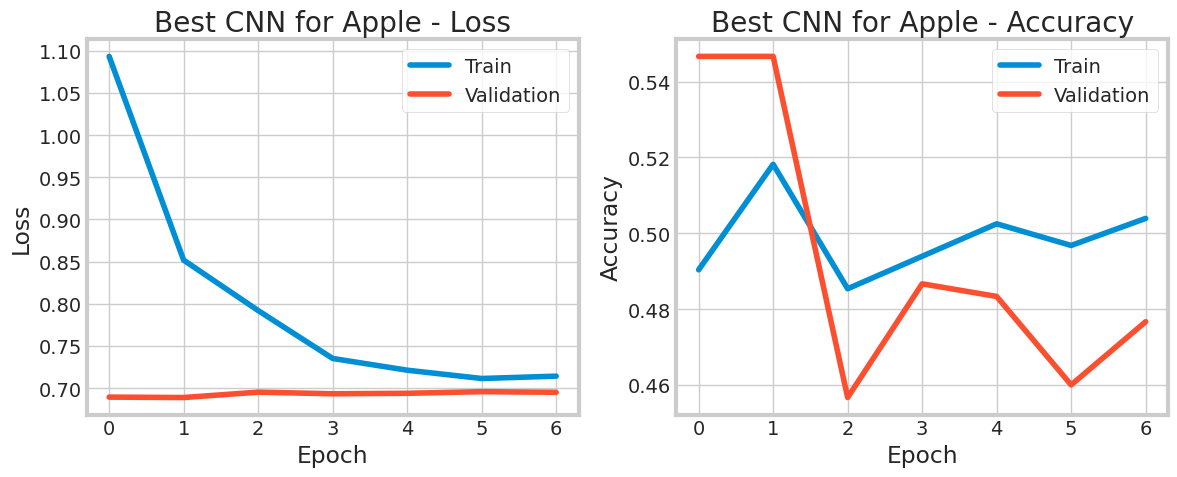


Training CNN-LSTM for Apple with 4 parameter combinations
Testing parameters: CNNLSTM-Baseline


Model: "functional_63"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_24 (InputLayer)     │ (None, 10, 12)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_12 (Conv1D)              │ (None, 8, 64)          │         2,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_12 (MaxPooling1D) │ (None, 4, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_40 (Dropout)            │ (None, 4, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_19 (LSTM)                  │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_41 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_48 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_42 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_49 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 37,505 (146.50 KB)

 Trainable params: 37,505 (146.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.5563 - loss: 0.6894 - val_accuracy: 0.4533 - val_loss: 0.7005 - learning_rate: 0.0010
Epoch 2/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.5070 - loss: 0.7019 - val_accuracy: 0.4533 - val_loss: 0.7082 - learning_rate: 0.0010
Epoch 3/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.4929 - loss: 0.6962 - val_accuracy: 0.4533 - val_loss: 0.6952 - learning_rate: 0.0010
Epoch 4/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.5228 - loss: 0.6902 - val_accuracy: 0.4500 - val_loss: 0.6938 - learning_rate: 0.0010
Epoch 5/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.5309 - loss: 0.6928 - val_accuracy: 0.4433 - val_loss: 0.6944 - learning_rate: 0.0010
Epoch 6/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.5103 - loss: 0.6959 - val_accuracy: 0.5467 - val_loss: 0.6916 - learning_rate: 0.0010
Epoch 7/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.5202 - loss: 0.6916 - val_accur

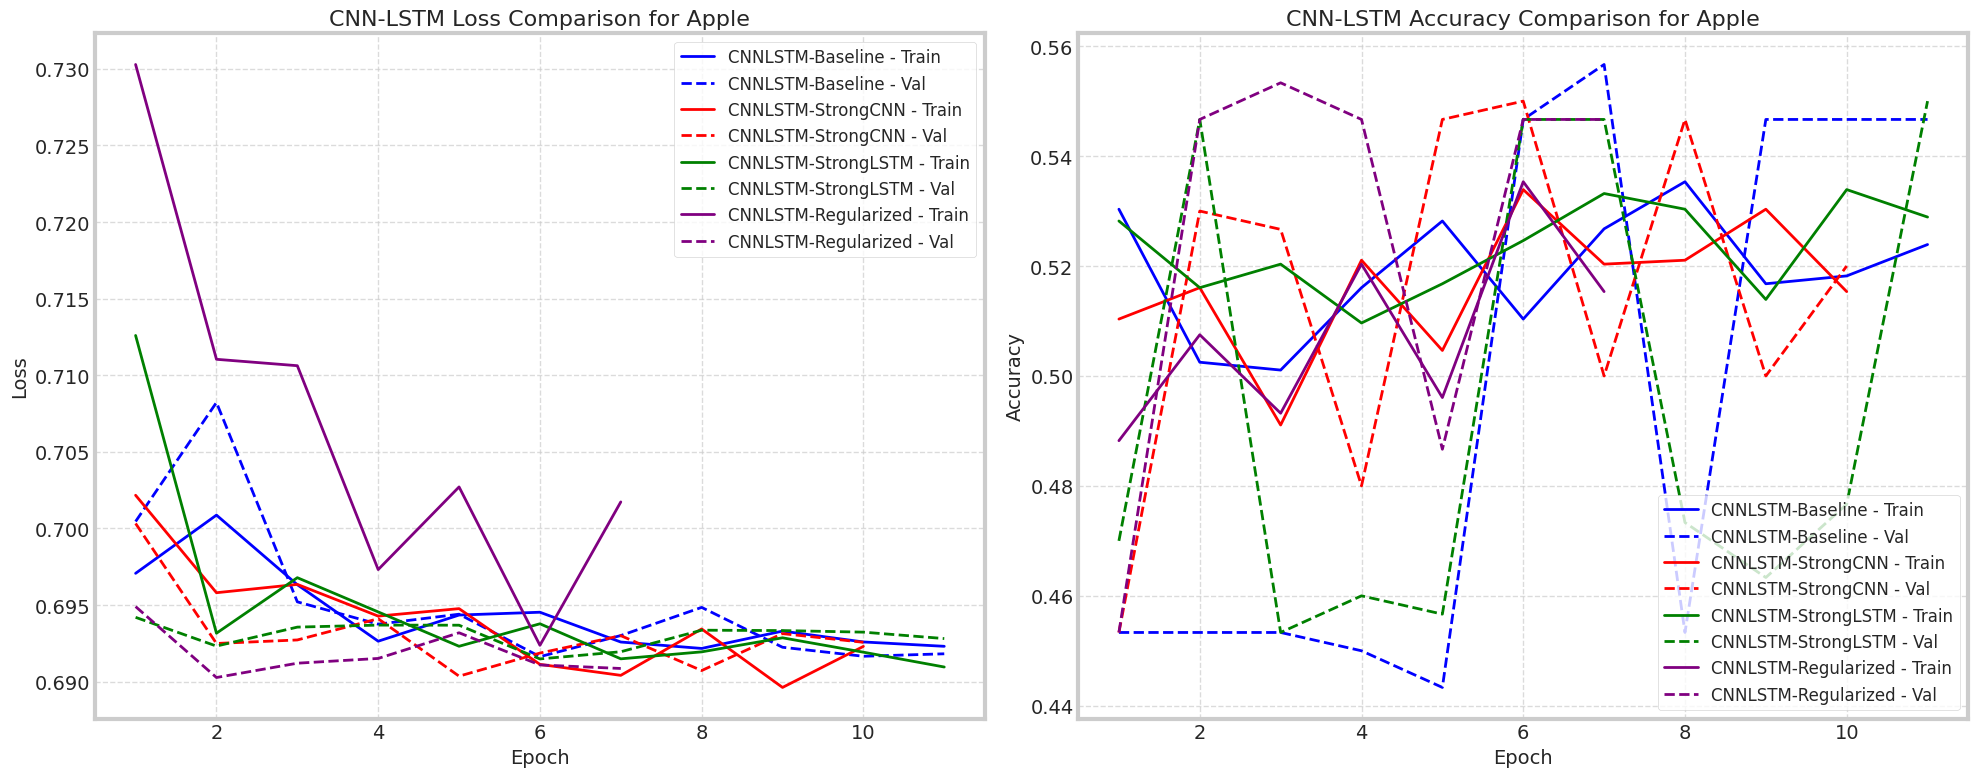

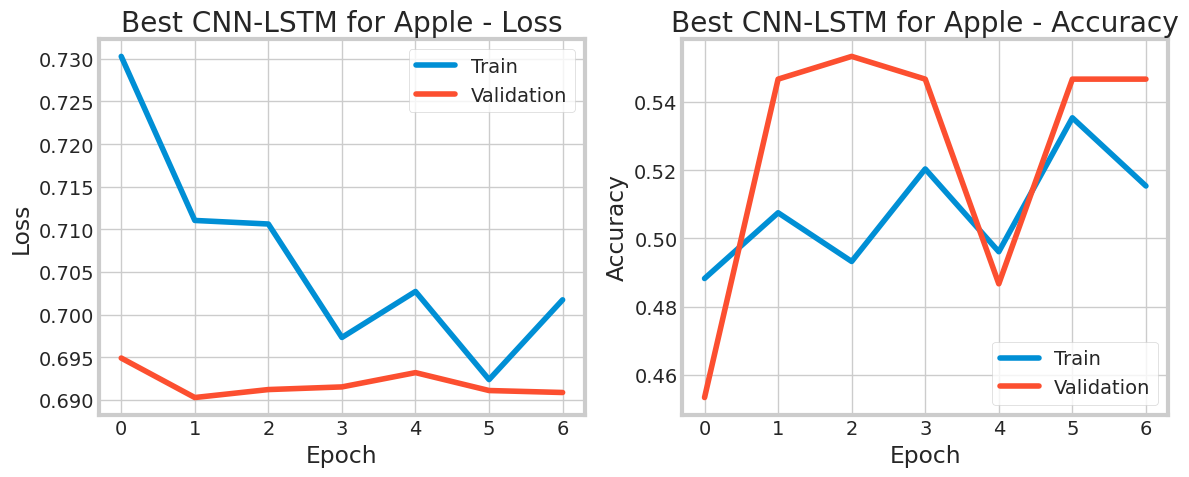


Training CNN for Microsoft with 4 parameter combinations
Testing parameters: CNN-Baseline


Model: "sequential_20"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_16 (Conv1D)              │ (None, 8, 64)          │         2,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_16 (MaxPooling1D) │ (None, 4, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_52 (Dropout)            │ (None, 4, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_8 (Flatten)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_56 (Dense)                │ (None, 32)             │         8,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_53 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_57 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,625 (41.50 KB)

 Trainable params: 10,625 (41.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 5s 62ms/step - accuracy: 0.4916 - loss: 1.2371 - val_accuracy: 0.4967 - val_loss: 0.6973 - learning_rate: 0.0010
Epoch 2/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4603 - loss: 0.7344 - val_accuracy: 0.5033 - val_loss: 0.6935 - learning_rate: 0.0010
Epoch 3/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4932 - loss: 0.6984 - val_accuracy: 0.5033 - val_loss: 0.6929 - learning_rate: 0.0010
Epoch 4/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4938 - loss: 0.6954 - val_accuracy: 0.4967 - val_loss: 0.6932 - learning_rate: 0.0010
Epoch 5/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5139 - loss: 0.6943 - val_accuracy: 0.4967 - val_loss: 0.6932 - learning_rate: 0.0010
Epoch 6/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5209 - loss: 0.6922 - val_accuracy: 0.4967 - val_loss: 0.6932 - learning_rate: 5.0000e-04
Epoch 7/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5112 - loss: 0.6950 - val_accur

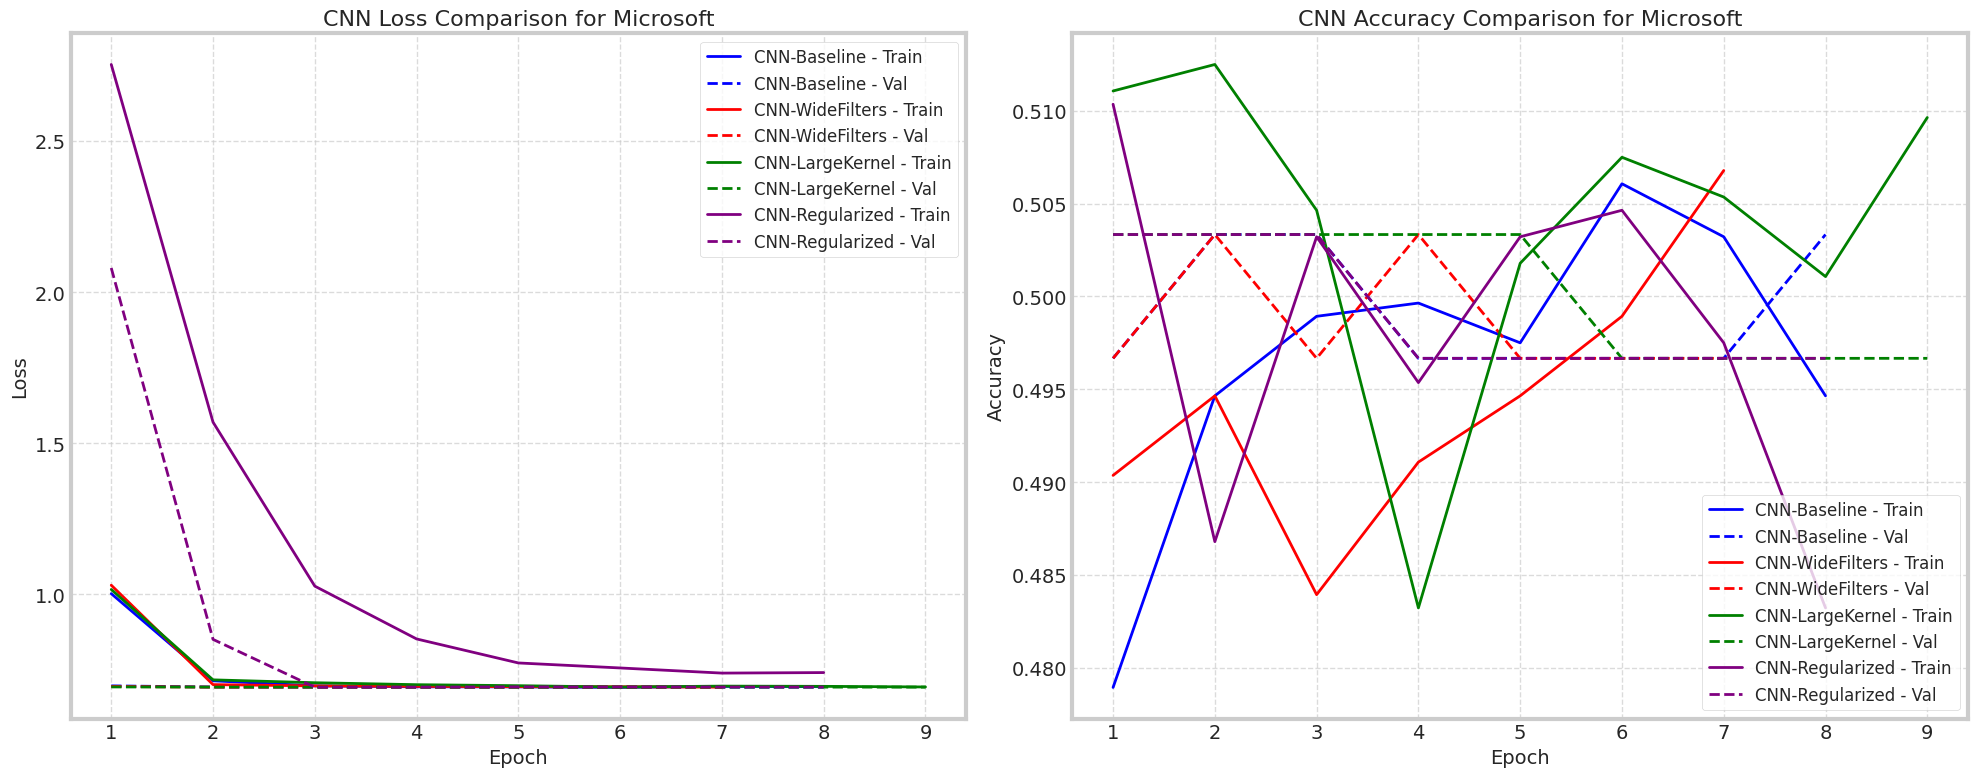

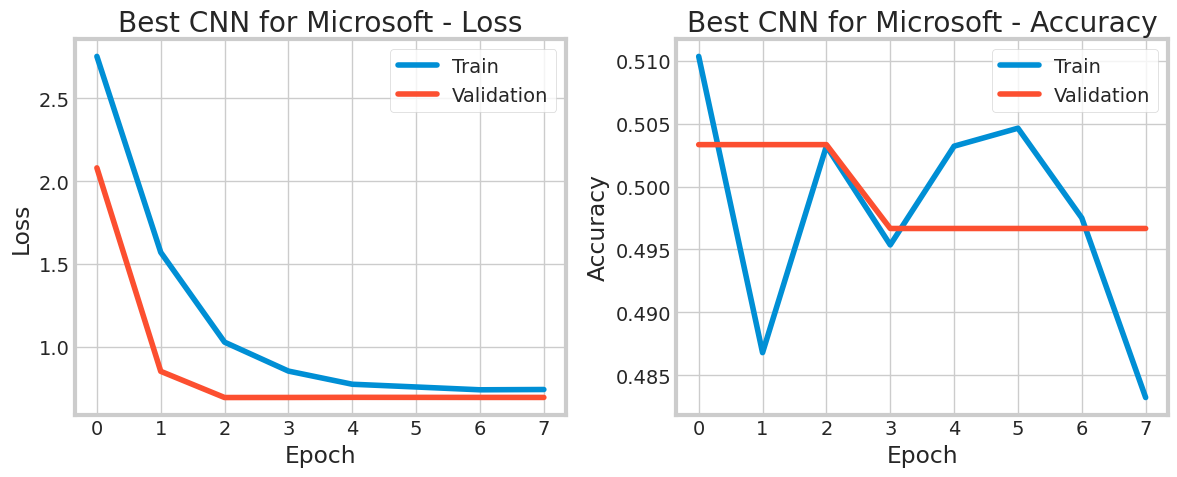


Training CNN-LSTM for Microsoft with 4 parameter combinations
Testing parameters: CNNLSTM-Baseline


Model: "functional_71"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_32 (InputLayer)     │ (None, 10, 12)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_20 (Conv1D)              │ (None, 8, 64)          │         2,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_20 (MaxPooling1D) │ (None, 4, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_60 (Dropout)            │ (None, 4, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_23 (LSTM)                  │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_61 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_64 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_62 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_65 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 37,505 (146.50 KB)

 Trainable params: 37,505 (146.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.5000 - loss: 0.7150 - val_accuracy: 0.5033 - val_loss: 0.6942 - learning_rate: 0.0010
Epoch 2/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.5215 - loss: 0.7011 - val_accuracy: 0.5033 - val_loss: 0.6982 - learning_rate: 0.0010
Epoch 3/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.5071 - loss: 0.6978 - val_accuracy: 0.4867 - val_loss: 0.6936 - learning_rate: 0.0010
Epoch 4/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.4861 - loss: 0.6987 - val_accuracy: 0.5033 - val_loss: 0.6941 - learning_rate: 0.0010
Epoch 5/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5100 - loss: 0.6965 - val_accuracy: 0.5033 - val_loss: 0.6933 - learning_rate: 0.0010
Epoch 6/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.4837 - loss: 0.6968 - val_accuracy: 0.5033 - val_loss: 0.6934 - learning_rate: 0.0010
Epoch 7/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.4941 - loss: 0.6977 - val_acc

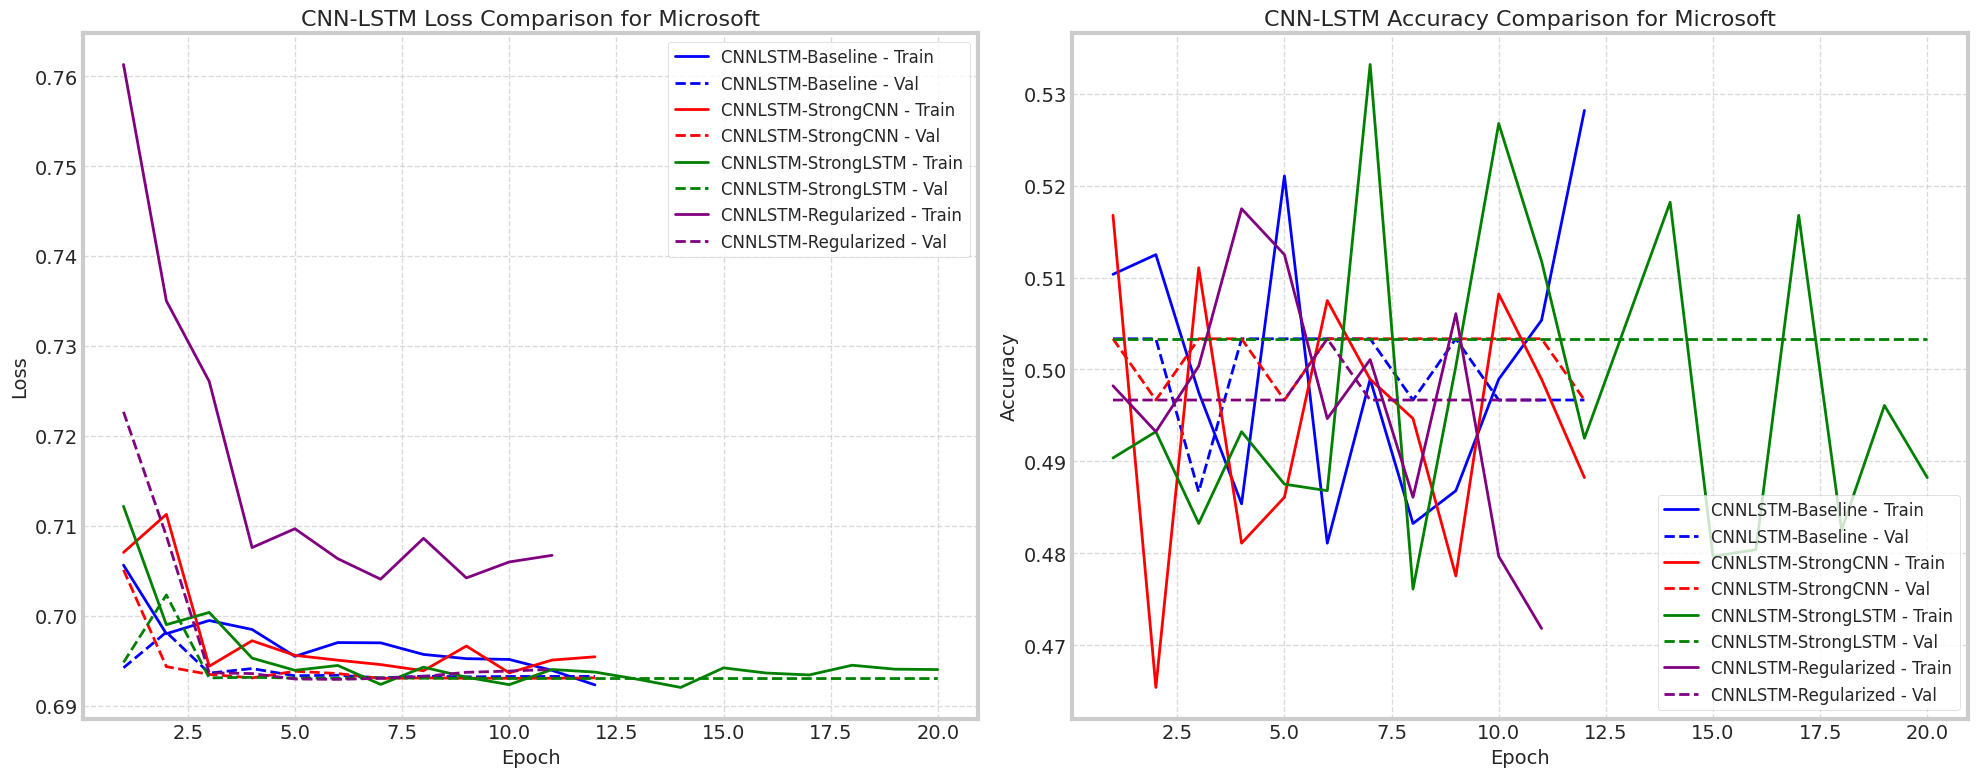

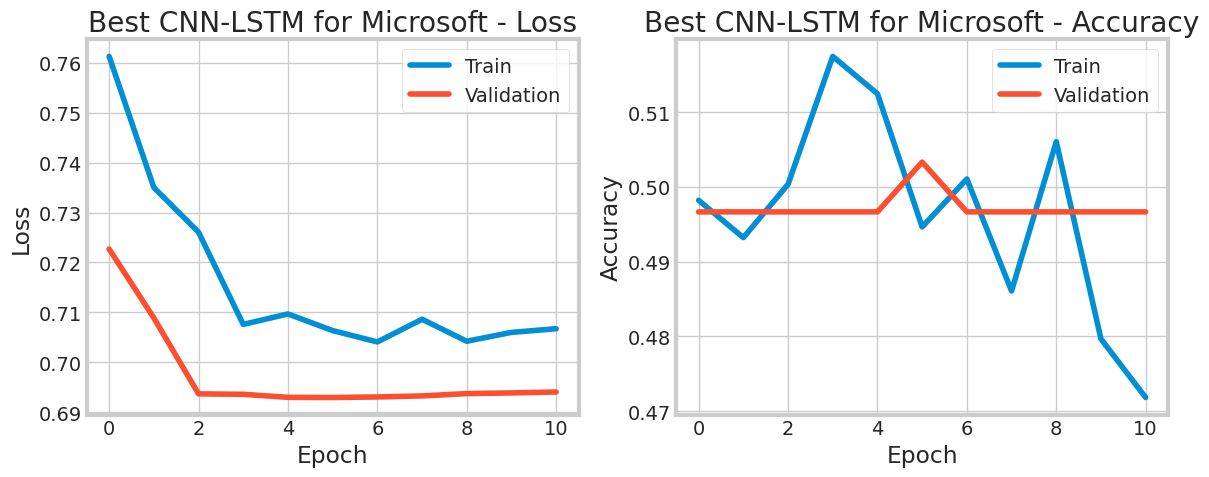

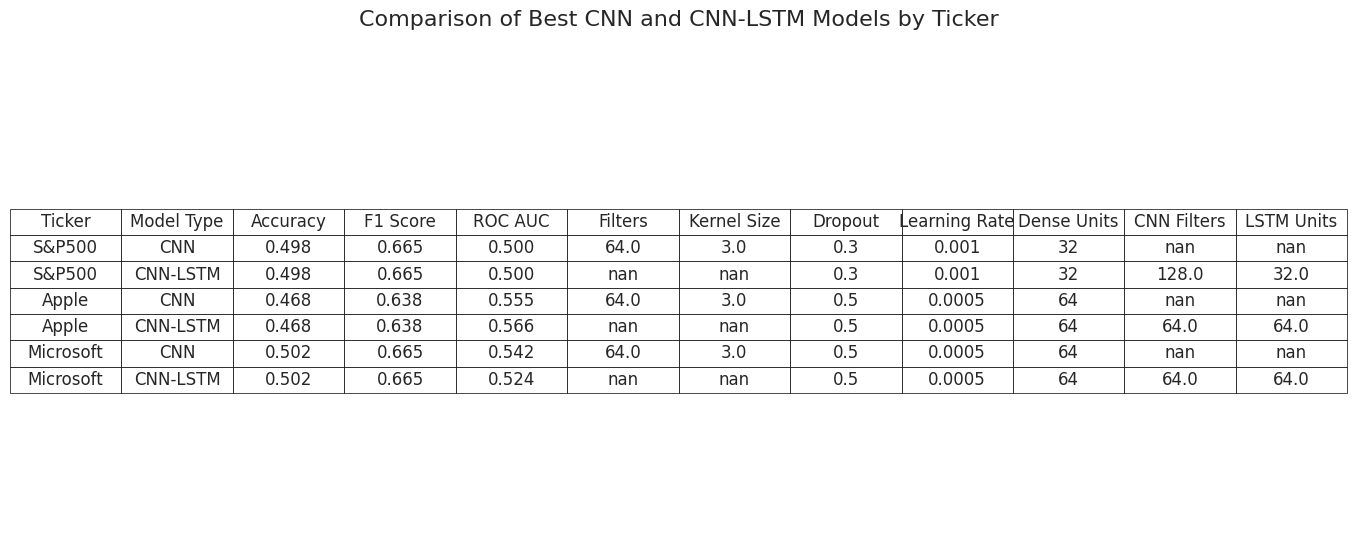

In [15]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, optimizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, roc_auc_score
import numpy as np
import pandas as pd
tf.random.set_seed(RANDOM_SEED)

# Function to visualize model training history
def plot_training_history(history, title):
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title(f'{title} - Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(['Train', 'Validation'])
    plt.subplot(1, 2, 2)
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.title(f'{title} - Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(['Train', 'Validation'])
    plt.tight_layout()
    plt.show()

# CNN model builder
def build_cnn(input_shape, filters=64, kernel_size=3, dropout=0.2, lr=0.001, dense_units=32):
    """Build CNN model with given hyperparameters"""
    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv1D(filters, kernel_size=kernel_size, activation='relu'),
        layers.MaxPooling1D(),
        layers.Dropout(dropout),
        layers.Flatten(),
        layers.Dense(dense_units, activation='relu'),
        layers.Dropout(dropout),
        layers.Dense(1, activation='sigmoid')
    ])
    optimizer = optimizers.Adam(learning_rate=lr)
    model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])
    return model

# CNN-LSTM hybrid model builder
def build_cnn_lstm(input_shape, cnn_filters=64, lstm_units=64, dropout=0.2, lr=0.001, dense_units=32):
    """Build CNN-LSTM hybrid model with given hyperparameters"""
    inp = layers.Input(shape=input_shape)
    x = layers.Conv1D(cnn_filters, kernel_size=3, activation='relu')(inp)
    x = layers.MaxPooling1D()(x)
    x = layers.Dropout(dropout)(x)
    x = layers.LSTM(lstm_units)(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(dense_units, activation='relu')(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(1, activation='sigmoid')(x)
    model = models.Model(inp, out)
    optimizer = optimizers.Adam(learning_rate=lr)
    model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])
    return model

# Create diverse parameter combinations for CNN
def create_diverse_cnn_params(max_combinations=4):
    param_combinations = [
        # Baseline configuration
        {
            'filters': 64,
            'kernel_size': 3,
            'dropout': 0.3,
            'lr': 0.001,
            'dense_units': 32,
            'name': 'CNN-Baseline'
        },
        # Wide filters
        {
            'filters': 128,
            'kernel_size': 3,
            'dropout': 0.3,
            'lr': 0.001,
            'dense_units': 32,
            'name': 'CNN-WideFilters'
        },
        # Large kernel
        {
            'filters': 64,
            'kernel_size': 5,
            'dropout': 0.3,
            'lr': 0.001,
            'dense_units': 32,
            'name': 'CNN-LargeKernel'
        },
        # Regularized
        {
            'filters': 64,
            'kernel_size': 3,
            'dropout': 0.5,
            'lr': 0.0005,
            'dense_units': 64,
            'name': 'CNN-Regularized'
        }
    ]
    return param_combinations

# Create diverse parameter combinations for CNN-LSTM
def create_diverse_cnn_lstm_params(max_combinations=4):
    param_combinations = [
        # Baseline configuration
        {
            'cnn_filters': 64,
            'lstm_units': 64,
            'dropout': 0.3,
            'lr': 0.001,
            'dense_units': 32,
            'name': 'CNNLSTM-Baseline'
        },
        # Strong CNN component
        {
            'cnn_filters': 128,
            'lstm_units': 32,
            'dropout': 0.3,
            'lr': 0.001,
            'dense_units': 32,
            'name': 'CNNLSTM-StrongCNN'
        },
        # Strong LSTM component
        {
            'cnn_filters': 32,
            'lstm_units': 128,
            'dropout': 0.3,
            'lr': 0.001,
            'dense_units': 32,
            'name': 'CNNLSTM-StrongLSTM'
        },
        # Highly regularized
        {
            'cnn_filters': 64,
            'lstm_units': 64,
            'dropout': 0.5,
            'lr': 0.0005,
            'dense_units': 64,
            'name': 'CNNLSTM-Regularized'
        }
    ]
    return param_combinations

# Function to train and evaluate models with parameter combinations
def train_with_hyperparams(model_type, build_func, param_combinations, ticker, data, splits, dl_results):
    X_tr, y_tr, X_val, y_val, X_te, y_te = splits['full'][ticker]
    # Define callbacks for training
    callbacks_list = [
        EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=0.00001)
    ]
    # Initialize tracking
    best_val_loss = float('inf')
    best_params = None
    best_model = None
    best_history = None
    # Store all training histories
    ticker_results = {
        'loss_data': [],
        'acc_data': [],
        'val_loss_data': [],
        'val_acc_data': [],
        'param_names': []
    }
    # Colors for plotting
    colors = ['blue', 'red', 'green', 'purple']
    print(f"\nTraining {model_type} for {ticker} with {len(param_combinations)} parameter combinations")
    # Training loop for all parameter combinations
    for i, params in enumerate(param_combinations):
        print(f"Testing parameters: {params['name']}")
        # Build model with current parameters
        if model_type == 'CNN':
            model = build_func(
                X_tr.shape[1:],
                filters=params['filters'],
                kernel_size=params['kernel_size'],
                dropout=params['dropout'],
                lr=params['lr'],
                dense_units=params['dense_units']
            )
        else:  # CNN-LSTM
            model = build_func(
                X_tr.shape[1:],
                cnn_filters=params['cnn_filters'],
                lstm_units=params['lstm_units'],
                dropout=params['dropout'],
                lr=params['lr'],
                dense_units=params['dense_units']
            )
        # Display model summary for first model only
        if i == 0:
            model.summary()
        # Train the model
        history = model.fit(
            X_tr, y_tr,
            validation_data=(X_val, y_val),
            epochs=EPOCHS,
            batch_size=BATCH_SIZE,
            callbacks=callbacks_list,
            verbose=1
        )
        # Check if this model is better
        val_loss = min(history.history['val_loss'])
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_params = {k: v for k, v in params.items() if k != 'name'}
            best_model = model
            best_history = history
        # Store training history for visualization
        ticker_results['loss_data'].append((history.history['loss'], colors[i]))
        ticker_results['val_loss_data'].append((history.history['val_loss'], colors[i]))
        ticker_results['acc_data'].append((history.history['accuracy'], colors[i]))
        ticker_results['val_acc_data'].append((history.history['val_accuracy'], colors[i]))
        ticker_results['param_names'].append(params['name'])

        # MODIFICATION 1: Evaluate each model configuration with adaptive threshold for Microsoft
        test_loss, test_acc = model.evaluate(X_te, y_te, verbose=0)
        y_pred_proba = model.predict(X_te, verbose=0).flatten()

        # Adaptive threshold specifically for Microsoft
        if ticker == "Microsoft":
            best_f1 = 0
            best_threshold = 0.5
            # Try a range of thresholds to find optimal value
            for threshold in np.arange(0.2, 0.8, 0.05):
                tmp_pred = (y_pred_proba > threshold).astype(int)
                tmp_f1 = f1_score(y_te, tmp_pred)
                if tmp_f1 > best_f1:
                    best_f1 = tmp_f1
                    best_threshold = threshold

            y_pred = (y_pred_proba > best_threshold).astype(int)
            f1 = best_f1
            roc = roc_auc_score(y_te, y_pred_proba)
            print(f"{ticker} - {params['name']} - Test Accuracy: {test_acc:.3f}, F1: {f1:.3f} (threshold={best_threshold:.2f}), ROC AUC: {roc:.3f}")
        else:
            # Original code for other tickers
            y_pred = (y_pred_proba > 0.5).astype(int)
            f1 = f1_score(y_te, y_pred)
            roc = roc_auc_score(y_te, y_pred_proba)
            print(f"{ticker} - {params['name']} - Test Accuracy: {test_acc:.3f}, F1: {f1:.3f}, ROC AUC: {roc:.3f}")

    # MODIFICATION 2: Evaluate best model on test set with adaptive threshold for Microsoft
    test_loss, test_acc = best_model.evaluate(X_te, y_te, verbose=0)
    y_pred_proba = best_model.predict(X_te, verbose=0).flatten()

    # Adaptive threshold specifically for Microsoft's best model
    if ticker == "Microsoft":
        best_f1 = 0
        best_threshold = 0.5
        # Use a finer-grained search for the best model
        for threshold in np.arange(0.2, 0.8, 0.02):
            tmp_pred = (y_pred_proba > threshold).astype(int)
            tmp_f1 = f1_score(y_te, tmp_pred)
            if tmp_f1 > best_f1:
                best_f1 = tmp_f1
                best_threshold = threshold

        print(f"{ticker} - {model_type} - Best threshold for final model: {best_threshold:.2f} with F1 = {best_f1:.3f}")
        y_pred = (y_pred_proba > best_threshold).astype(int)
        f1 = best_f1
    else:
        # Original code for other tickers
        y_pred = (y_pred_proba > 0.5).astype(int)
        f1 = f1_score(y_te, y_pred)

    roc = roc_auc_score(y_te, y_pred_proba)

    # Store best model results
    if model_type not in dl_results[ticker]:
        dl_results[ticker][model_type] = {}
    dl_results[ticker][model_type] = {
        'model': best_model,
        'history': best_history,
        'params': best_params,
        'acc': test_acc,
        'f1': f1,
        'roc': roc,
        'y_test': y_te,
        'y_pred': y_pred,
        'y_pred_proba': y_pred_proba
    }
    print(f"{ticker} – {model_type} Best Model Test Accuracy: {test_acc:.3f}, F1: {f1:.3f}, ROC AUC: {roc:.3f}")
    # Plot all training results in a single figure
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))
    # Plot loss
    ax1.set_title(f'{model_type} Loss Comparison for {ticker}', fontsize=16)
    ax1.set_xlabel('Epoch', fontsize=14)
    ax1.set_ylabel('Loss', fontsize=14)
    for i, ((loss_data, color), (val_loss_data, val_color), param_name) in enumerate(zip(
        ticker_results['loss_data'],
        ticker_results['val_loss_data'],
        ticker_results['param_names']
    )):
        epochs = range(1, len(loss_data) + 1)
        ax1.plot(epochs, loss_data, color=color, linestyle='-',
                 linewidth=2, label=f'{param_name} - Train')
        ax1.plot(epochs, val_loss_data, color=color, linestyle='--',
                 linewidth=2, label=f'{param_name} - Val')
    ax1.legend(loc='upper right', fontsize=12)
    ax1.grid(True, linestyle='--', alpha=0.7)
    # Plot accuracy
    ax2.set_title(f'{model_type} Accuracy Comparison for {ticker}', fontsize=16)
    ax2.set_xlabel('Epoch', fontsize=14)
    ax2.set_ylabel('Accuracy', fontsize=14)
    for i, ((acc_data, color), (val_acc_data, val_color), param_name) in enumerate(zip(
        ticker_results['acc_data'],
        ticker_results['val_acc_data'],
        ticker_results['param_names']
    )):
        epochs = range(1, len(acc_data) + 1)
        ax2.plot(epochs, acc_data, color=color, linestyle='-',
                 linewidth=2, label=f'{param_name} - Train')
        ax2.plot(epochs, val_acc_data, color=color, linestyle='--',
                 linewidth=2, label=f'{param_name} - Val')
    ax2.legend(loc='lower right', fontsize=12)
    ax2.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
    # Also show the traditional single plot for the best model
    plot_training_history(best_history, f'Best {model_type} for {ticker}')
    return dl_results

# Main execution code
EPOCHS = 20
BATCH_SIZE = 32
PATIENCE = 5
# Training CNN models with hyperparameter search
for ticker, (X, y) in seq_data['full'].items():
    if ticker not in dl_results:
        dl_results[ticker] = {}
    # Generate parameter combinations for CNN
    cnn_param_combinations = create_diverse_cnn_params(max_combinations=4)
    # Train CNN models
    dl_results = train_with_hyperparams(
        'CNN',
        build_cnn,
        cnn_param_combinations,
        ticker,
        seq_data['full'],
        splits,
        dl_results
    )
    # Generate parameter combinations for CNN-LSTM
    cnn_lstm_param_combinations = create_diverse_cnn_lstm_params(max_combinations=4)
    # Train CNN-LSTM models
    dl_results = train_with_hyperparams(
        'CNN-LSTM',
        build_cnn_lstm,
        cnn_lstm_param_combinations,
        ticker,
        seq_data['full'],
        splits,
        dl_results
    )

# Create comparison table of best models for each ticker and model type
def create_model_comparison_table(results):
    data = []
    for ticker in results.keys():
        for model_type in ['CNN', 'CNN-LSTM']:
            if model_type in results[ticker]:
                info = results[ticker][model_type]
                model_row = {
                    'Ticker': ticker,
                    'Model Type': model_type,
                    'Accuracy': f"{info['acc']:.3f}",
                    'F1 Score': f"{info['f1']:.3f}",
                    'ROC AUC': f"{info['roc']:.3f}"
                }
                # Add specific parameters based on model type
                if model_type == 'CNN':
                    model_row.update({
                        'Filters': info['params']['filters'],
                        'Kernel Size': info['params']['kernel_size'],
                        'Dropout': info['params']['dropout'],
                        'Learning Rate': info['params']['lr'],
                        'Dense Units': info['params']['dense_units']
                    })
                else:  # CNN-LSTM
                    model_row.update({
                        'CNN Filters': info['params']['cnn_filters'],
                        'LSTM Units': info['params']['lstm_units'],
                        'Dropout': info['params']['dropout'],
                        'Learning Rate': info['params']['lr'],
                        'Dense Units': info['params']['dense_units']
                    })
                data.append(model_row)
    df = pd.DataFrame(data)
    # Plot comparison as a table
    rows = len(data)
    fig, ax = plt.subplots(figsize=(14, rows * 0.8 + 1))
    ax.axis('off')
    ax.axis('tight')
    table = ax.table(
        cellText=df.values,
        colLabels=df.columns,
        loc='center',
        cellLoc='center'
    )
    table.auto_set_font_size(False)
    table.set_fontsize(12)
    table.scale(1.2, 1.5)
    plt.title('Comparison of Best CNN and CNN-LSTM Models by Ticker', fontsize=16, pad=20)
    plt.tight_layout()
    plt.show()

# Display the comparison table
create_model_comparison_table(dl_results)

# CRISP-DM 5 – Evaluation & Comparison plots


Comparing model performance...

Comparing models for S&P500:


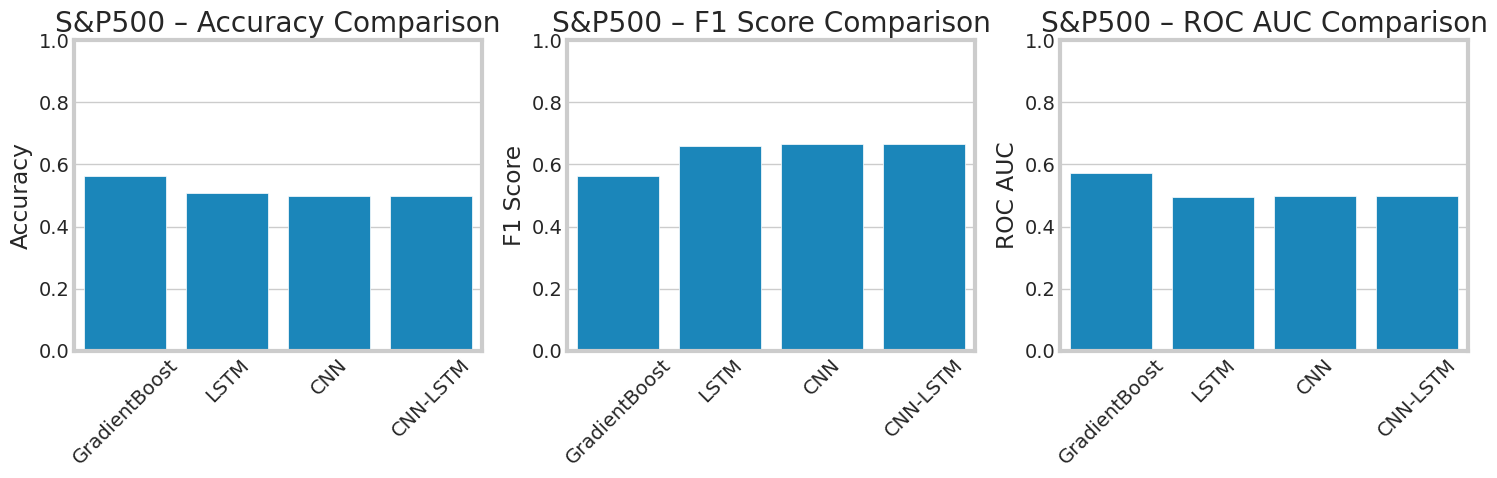

Best model for S&P500: GradientBoost

Comparing models for Apple:


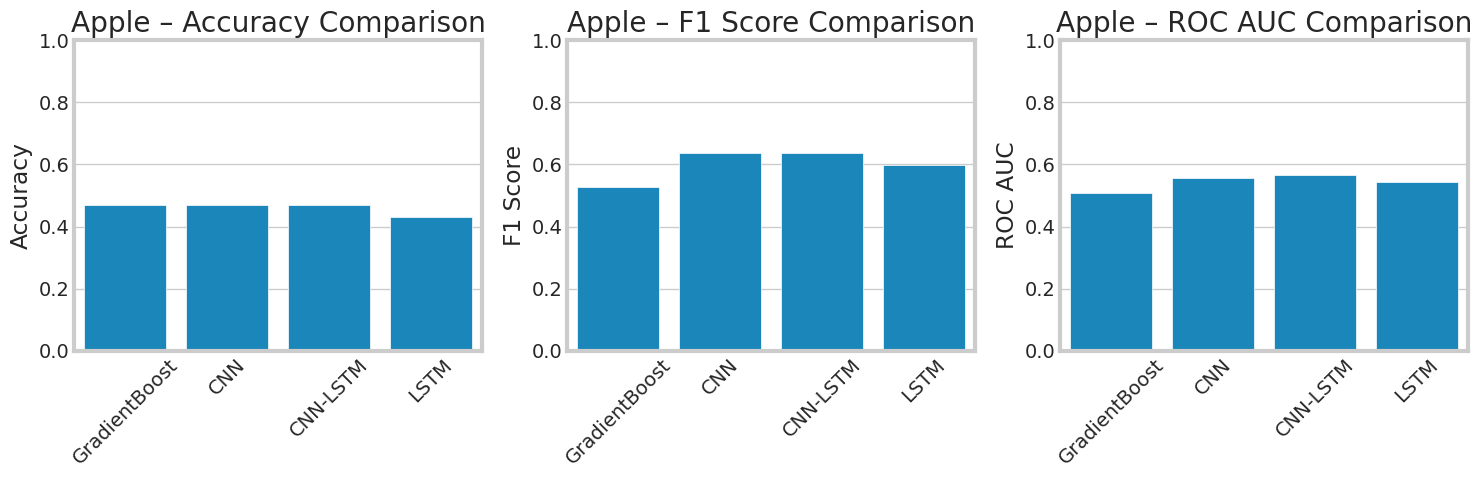

Best model for Apple: GradientBoost

Comparing models for Microsoft:


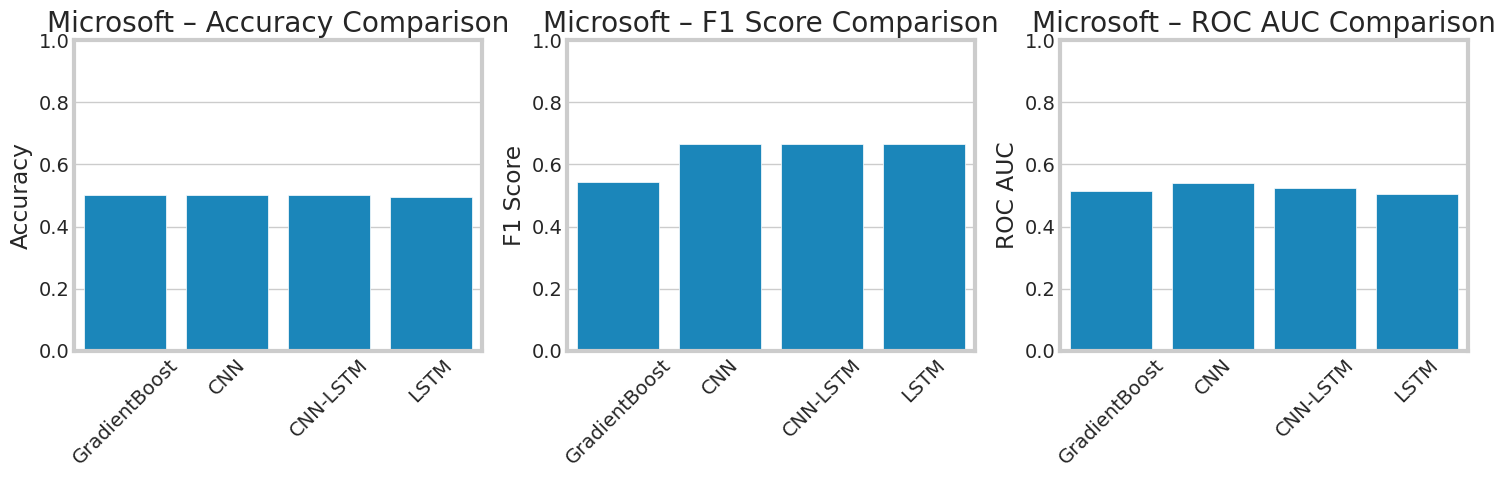

Best model for Microsoft: GradientBoost


In [16]:
def compare_models(ticker):
    """Compare all models for a given ticker"""
    # Get results for ML model
    ml_result = ml_results[ticker]

    # Get results for DL models
    lstm_result = dl_results[ticker]
    cnn_result = dl_results[ticker]['CNN']
    hybrid_result = dl_results[ticker]['CNN-LSTM']

    # Collect metrics
    models = ['GradientBoost', 'LSTM', 'CNN', 'CNN-LSTM']
    accuracy = [
        ml_result['acc'],
        lstm_result['acc'],
        cnn_result['acc'],
        hybrid_result['acc']
    ]
    f1_scores = [
        ml_result['f1'],
        lstm_result['f1'],
        cnn_result['f1'],
        hybrid_result['f1']
    ]
    roc_auc = [
        ml_result['roc'],
        lstm_result['roc'],
        cnn_result['roc'],
        hybrid_result['roc']
    ]

    # Sort by accuracy
    combined = list(zip(models, accuracy, f1_scores, roc_auc))
    combined.sort(key=lambda x: x[1], reverse=True)
    models, accuracy, f1_scores, roc_auc = zip(*combined)

    # Create comparison plots
    plt.figure(figsize=(15, 5))

    # Accuracy comparison
    plt.subplot(1, 3, 1)
    sns.barplot(x=list(models), y=list(accuracy))
    plt.title(f'{ticker} – Accuracy Comparison')
    plt.ylim(0, 1)
    plt.ylabel('Accuracy')
    plt.xticks(rotation=45)

    # F1 Score comparison
    plt.subplot(1, 3, 2)
    sns.barplot(x=list(models), y=list(f1_scores))
    plt.title(f'{ticker} – F1 Score Comparison')
    plt.ylim(0, 1)
    plt.ylabel('F1 Score')
    plt.xticks(rotation=45)

    # ROC AUC comparison
    plt.subplot(1, 3, 3)
    sns.barplot(x=list(models), y=list(roc_auc))
    plt.title(f'{ticker} – ROC AUC Comparison')
    plt.ylim(0, 1)
    plt.ylabel('ROC AUC')
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

    # Return the best model name
    return models[0]

# Run comparisons for each ticker
print("\nComparing model performance...")
best_models = {}

for ticker in tickers.keys():
    print(f"\nComparing models for {ticker}:")
    best_model = compare_models(ticker)
    best_models[ticker] = best_model
    print(f"Best model for {ticker}: {best_model}")

# CRISP-DM 5 – Explainability (SHAP for the baseline tree model)


Generating SHAP explanations for GradientBoost models...

SHAP analysis for S&P500:


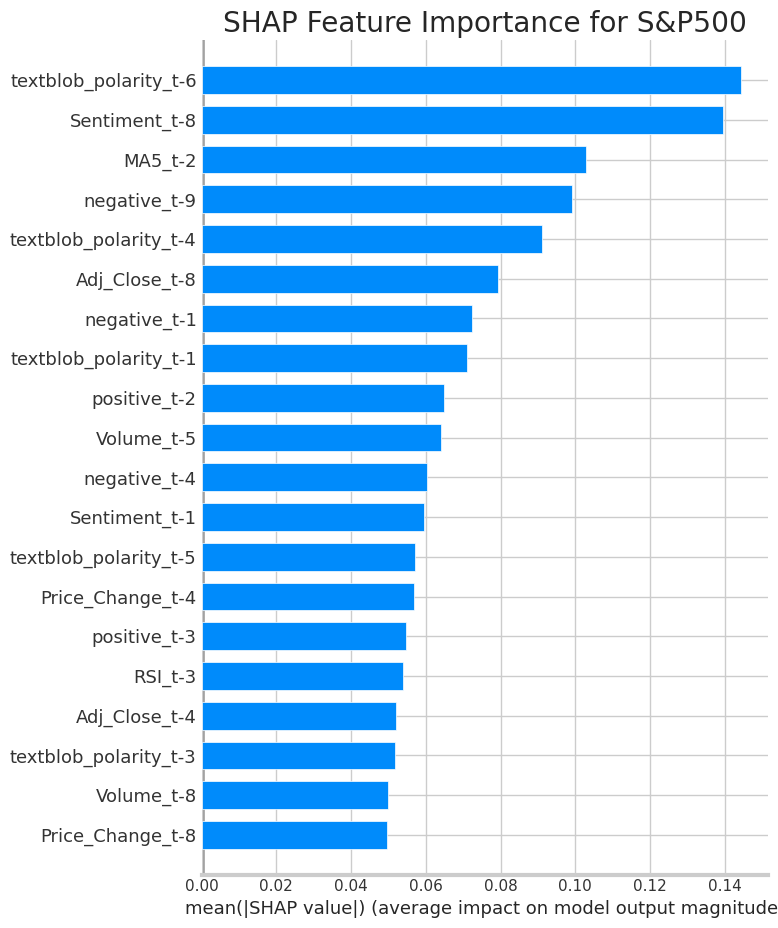


SHAP analysis for Apple:


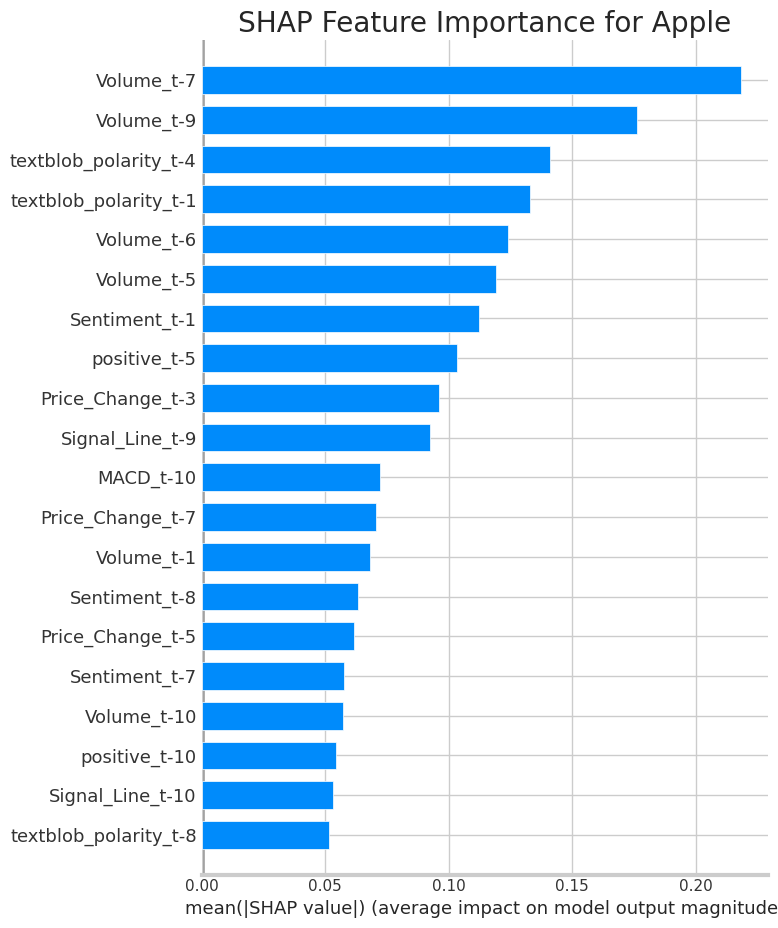


SHAP analysis for Microsoft:


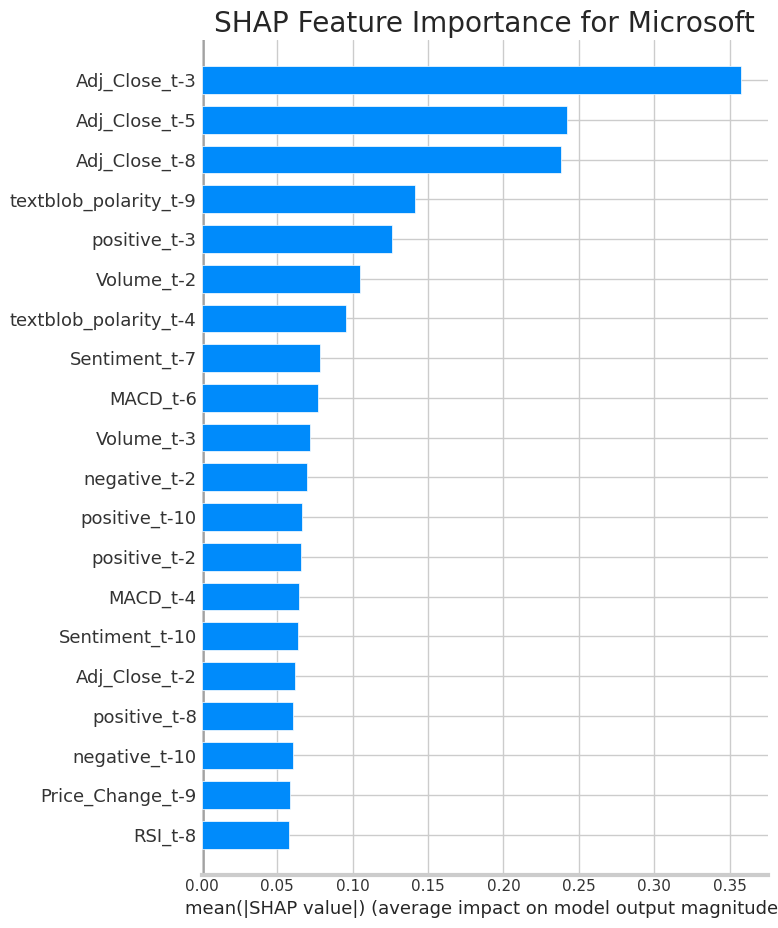

In [17]:
import shap
shap.initjs()

print("\nGenerating SHAP explanations for GradientBoost models...")

for ticker in tickers.keys():
    print(f"\nSHAP analysis for {ticker}:")

    # Get the model and feature names
    model = ml_results[ticker]['model']
    features = ml_results[ticker]['features']

    # Prepare feature names for the flattened window structure
    feature_names = []
    for t in range(lookback):
        for f in features:
            feature_names.append(f"{f}_t-{lookback-t}")

    # Get test data for SHAP analysis
    X_train, y_train, X_val, y_val, X_test, y_test = chrono_split(
        *prepare_ml_features(datasets[ticker], lookback, features)
    )

    # Use a sample of test data for speed
    sample_size = min(200, len(X_test))
    X_sample = X_test[:sample_size]

    # Create SHAP explainer
    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X_sample)

    # Summary plot
    plt.figure(figsize=(12, 8))
    shap.summary_plot(
        shap_values,
        pd.DataFrame(X_sample, columns=feature_names),
        plot_type='bar',
        show=False
    )
    plt.title(f'SHAP Feature Importance for {ticker}')
    plt.tight_layout()
    plt.show()

# CRISP-DM 6 – Model Explainability and Predictions



Generating XAI analysis and predictions...

Analyzing S&P500...


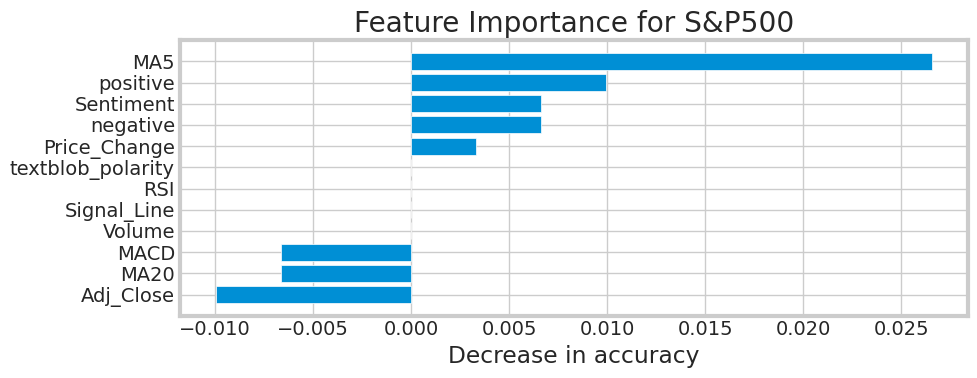

Top features for S&P500: [('MA5', np.float64(0.026578068733215332)), ('positive', np.float64(0.009966760873794556)), ('Sentiment', np.float64(0.006644517183303833))]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 263ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step


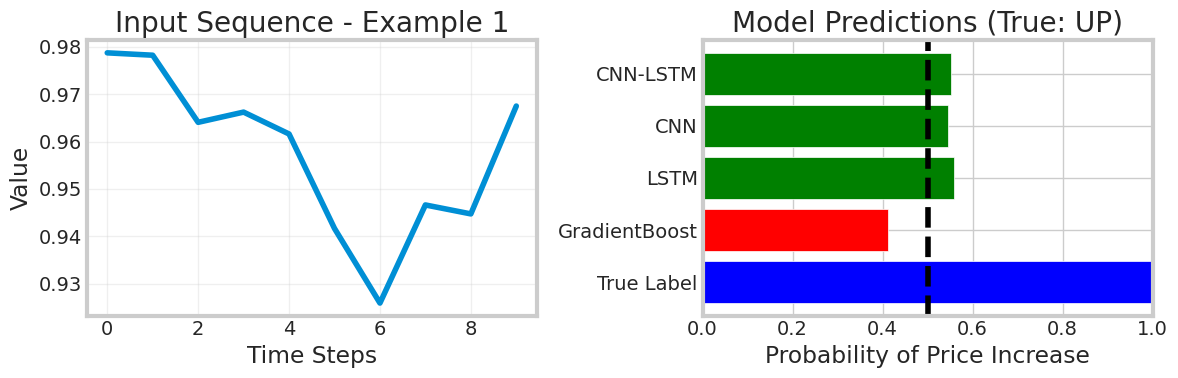

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step


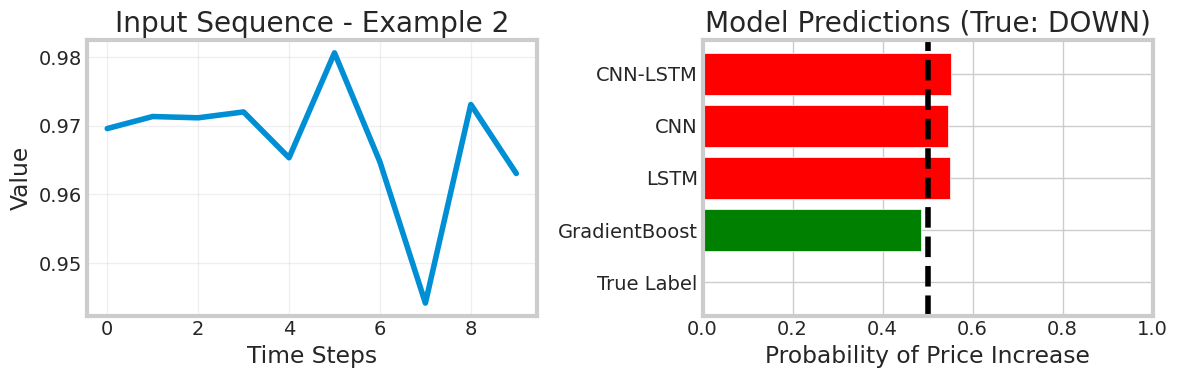

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step


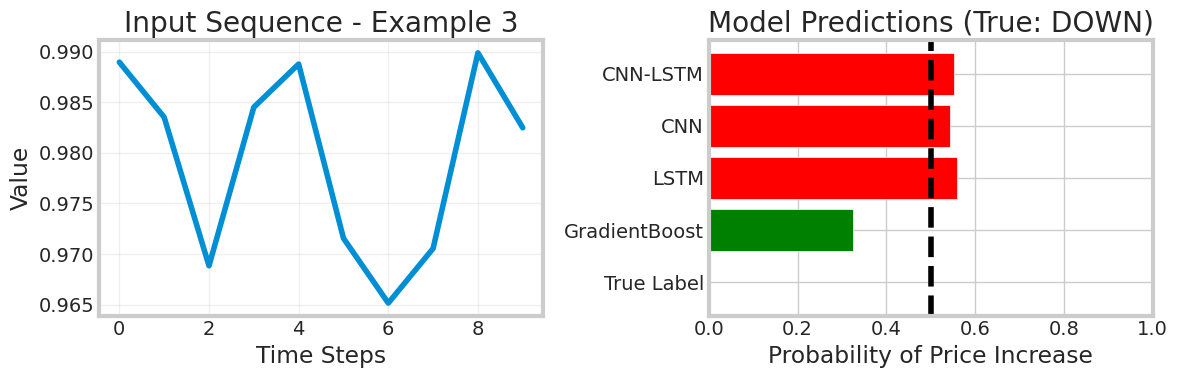


Model comparison for S&P500:
GradientBoost: ACC=0.561, F1=0.563, ROC=0.571
LSTM: ACC=0.508, F1=0.661, ROC=0.497
CNN: ACC=0.498, F1=0.665, ROC=0.500
CNN-LSTM: ACC=0.498, F1=0.665, ROC=0.500

Analyzing Apple...


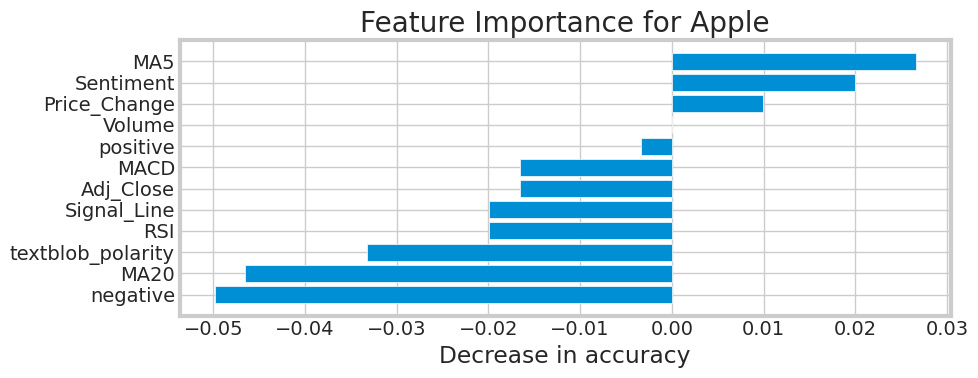

Top features for Apple: [('MA5', np.float64(0.026578068733215332)), ('Sentiment', np.float64(0.0199335515499115)), ('Price_Change', np.float64(0.009966760873794556))]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step


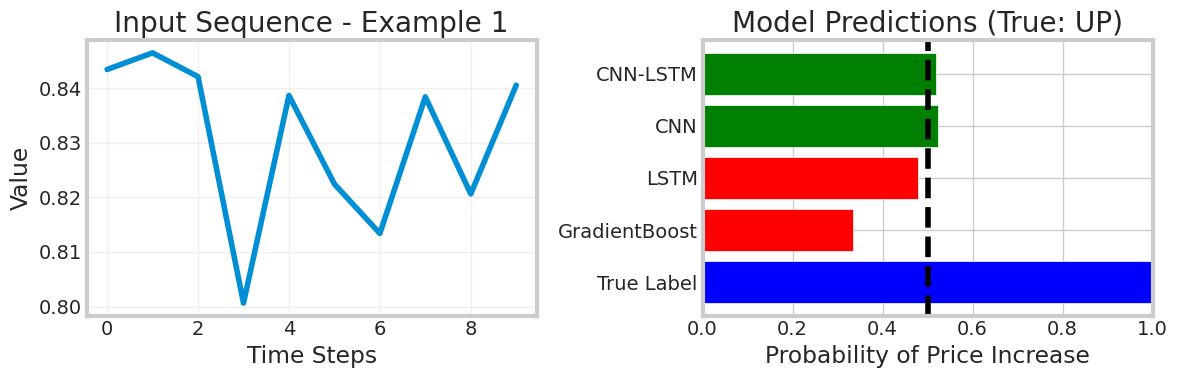

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step


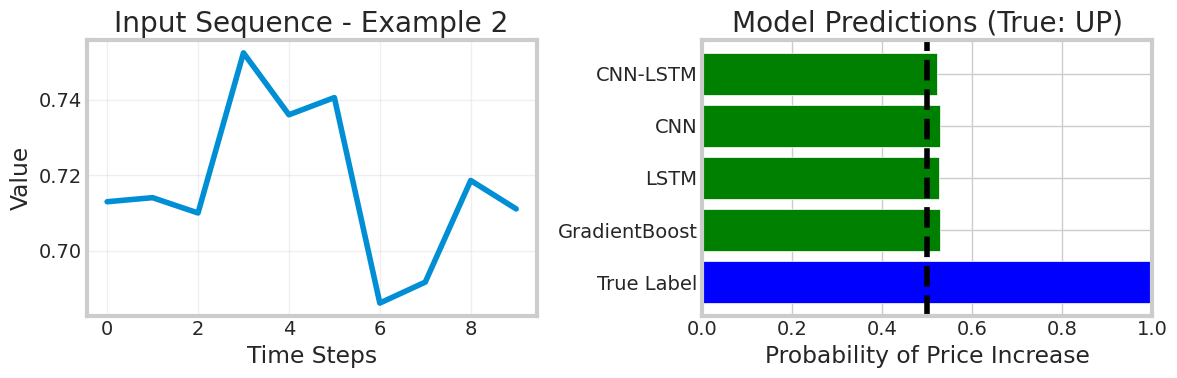

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step


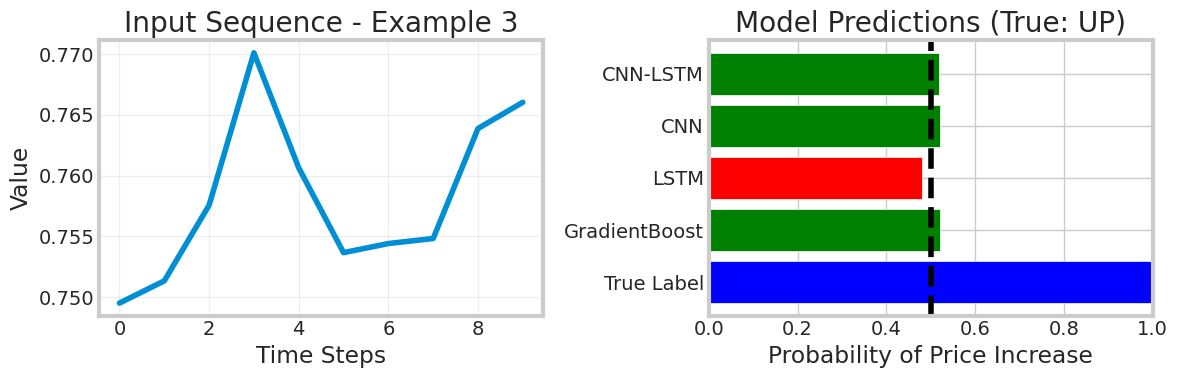


Model comparison for Apple:
GradientBoost: ACC=0.468, F1=0.527, ROC=0.509
LSTM: ACC=0.432, F1=0.597, ROC=0.543
CNN: ACC=0.468, F1=0.638, ROC=0.555
CNN-LSTM: ACC=0.468, F1=0.638, ROC=0.566

Analyzing Microsoft...


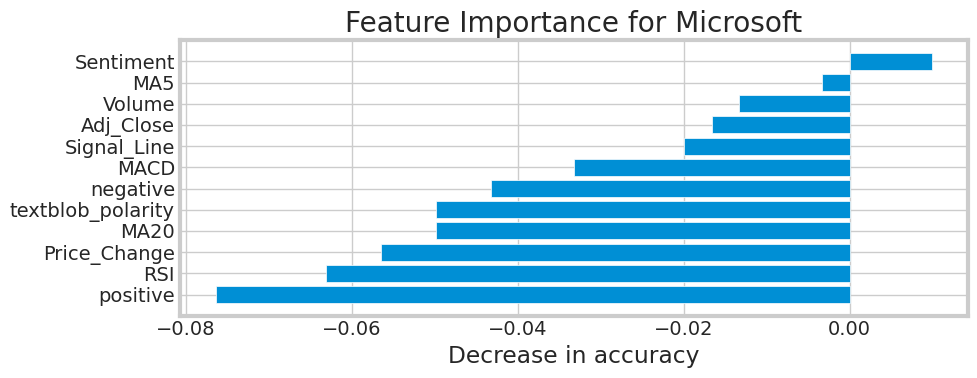

Top features for Microsoft: [('Sentiment', np.float64(0.009966790676116943)), ('MA5', np.float64(-0.0033222436904907227)), ('Volume', np.float64(-0.013289034366607666))]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step


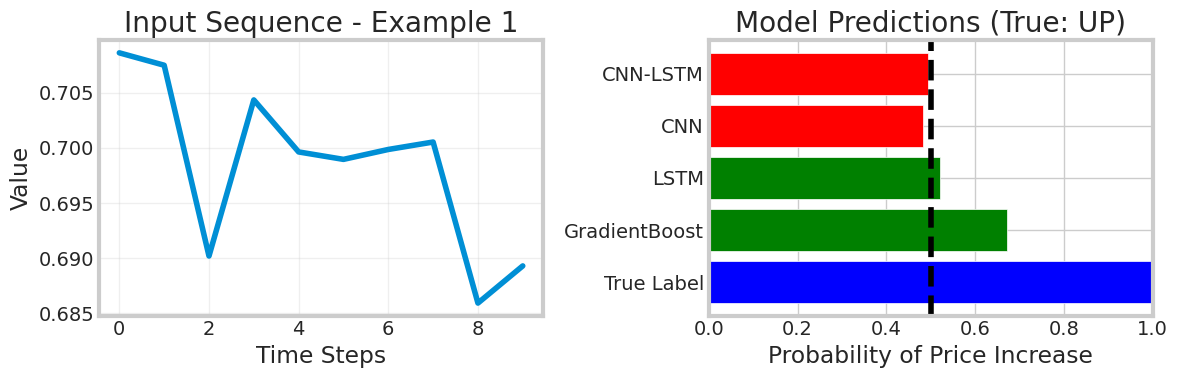

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step


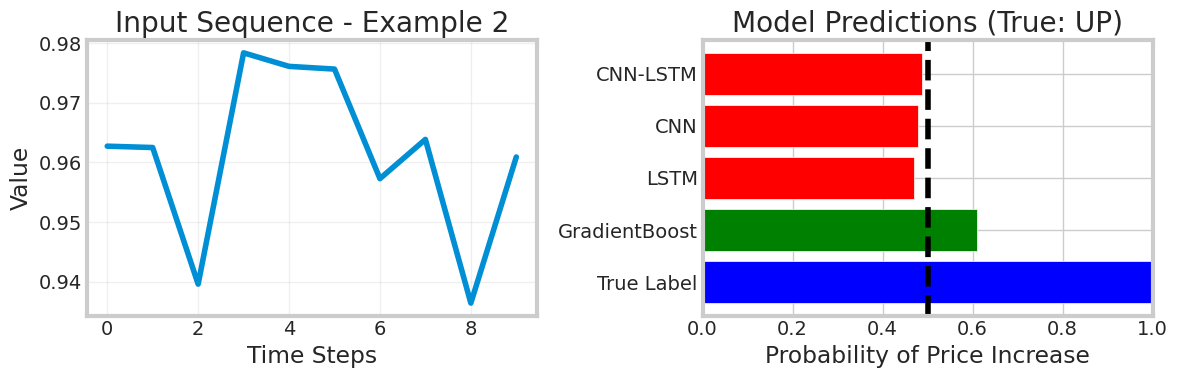

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


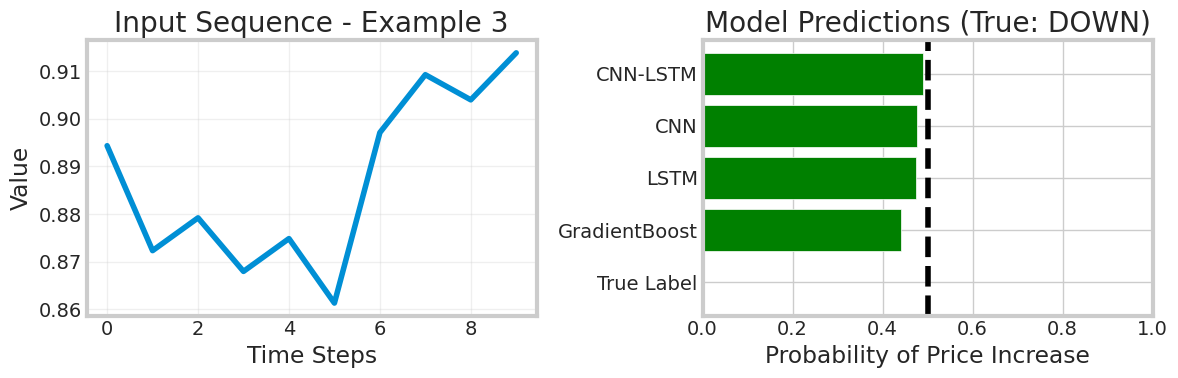


Model comparison for Microsoft:
GradientBoost: ACC=0.502, F1=0.543, ROC=0.514
LSTM: ACC=0.495, F1=0.665, ROC=0.505
CNN: ACC=0.502, F1=0.665, ROC=0.542
CNN-LSTM: ACC=0.502, F1=0.665, ROC=0.524

Analysis complete!


In [18]:
import shap
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import f1_score, roc_auc_score

# ----- 1. Feature Importance for all models -----
def plot_permutation_importance(model, X, y, features, ticker):
    """Plot permutation importance for a model"""
    baseline_score = model.evaluate(X, y, verbose=0)[1]  # Use accuracy
    importances = np.zeros(X.shape[2])

    # Calculate feature importance by permutation
    for i in range(X.shape[2]):
        X_permuted = X.copy()
        perm = np.random.permutation(len(X))
        X_permuted[:, :, i] = X_permuted[perm, :, i]
        score = model.evaluate(X_permuted, y, verbose=0)[1]
        importances[i] = baseline_score - score

    # Plot
    plt.figure(figsize=(10, 4))
    sorted_idx = np.argsort(importances)
    plt.barh(range(len(features)), importances[sorted_idx])
    plt.yticks(range(len(features)), np.array(features)[sorted_idx])
    plt.title(f"Feature Importance for {ticker}")
    plt.xlabel("Decrease in accuracy")
    plt.tight_layout()
    plt.show()

    return dict(zip(features, importances))

# ----- 2. Predictions Visualization -----
def visualize_predictions(ticker, X_test, y_test, models_dict):
    """Visualize predictions from different models"""
    # Select 3 random test examples
    n_examples = 3
    indices = np.random.choice(range(len(X_test)), n_examples)

    for i, idx in enumerate(indices):
        # Get sample data
        x = X_test[idx]
        true_label = y_test[idx]

        # Make predictions with each model
        preds = {}
        for name, model in models_dict.items():
            if name == 'GradientBoost':
                # Handle GB differently (needs flattened input)
                x_flat = x.flatten().reshape(1, -1)
                preds[name] = model.predict_proba(x_flat)[0, 1]
            else:
                preds[name] = model.predict(np.expand_dims(x, axis=0))[0, 0]

        # Plot predictions
        plt.figure(figsize=(12, 4))

        # 1. Plot input sequence
        plt.subplot(1, 2, 1)
        plt.plot(x[:, 0], label='Adj_Close (normalized)')
        plt.title(f'Input Sequence - Example {i+1}')
        plt.xlabel('Time Steps')
        plt.ylabel('Value')
        plt.grid(True, alpha=0.3)

        # 2. Plot model predictions
        plt.subplot(1, 2, 2)
        model_names = list(preds.keys())
        probs = [preds[m] for m in model_names]
        colors = ['green' if (p > 0.5) == true_label else 'red' for p in probs]

        # Insert ground truth at beginning
        model_names.insert(0, 'True Label')
        probs.insert(0, float(true_label))
        colors.insert(0, 'blue')

        plt.barh(model_names, probs, color=colors)
        plt.axvline(x=0.5, color='black', linestyle='--')
        plt.xlim(0, 1)
        plt.title(f'Model Predictions (True: {"UP" if true_label else "DOWN"})')
        plt.xlabel('Probability of Price Increase')

        plt.tight_layout()
        plt.show()

# ----- 3. Main execution -----
print("\nGenerating XAI analysis and predictions...")

for ticker in tickers.keys():
    print(f"\nAnalyzing {ticker}...")

    # Get data
    X_test = splits['full'][ticker][4]
    y_test = splits['full'][ticker][5]
    features = feature_sets['full']

    # Get all models for this ticker
    models = {
        'GradientBoost': ml_results[ticker]['model'],
        'LSTM': dl_results[ticker]['LSTM']['model']
    }

    if 'CNN' in dl_results[ticker]:
        models['CNN'] = dl_results[ticker]['CNN']['model']

    if 'CNN-LSTM' in dl_results[ticker]:
        models['CNN-LSTM'] = dl_results[ticker]['CNN-LSTM']['model']

    # 1. Feature importance for LSTM model
    importance = plot_permutation_importance(
        models['LSTM'], X_test, y_test, features, ticker
    )
    top_features = sorted(importance.items(), key=lambda x: x[1], reverse=True)[:3]
    print(f"Top features for {ticker}: {top_features}")

    # 2. Visualize actual predictions
    visualize_predictions(ticker, X_test, y_test, models)

    # 3. Print model performance comparison
    print(f"\nModel comparison for {ticker}:")
    for name, model in models.items():
        if name == 'GradientBoost':
            acc = ml_results[ticker]['acc']
            f1 = ml_results[ticker]['f1']
            roc = ml_results[ticker]['roc']
        else:
            model_key = dl_results[ticker][name]
            acc = model_key['acc']
            f1 = model_key['f1']
            roc = model_key['roc']
        print(f"{name}: ACC={acc:.3f}, F1={f1:.3f}, ROC={roc:.3f}")

print("\nAnalysis complete!")

# CRISP-DM 6 – Final Results and Summary


Final Results Summary:


,Ticker,Model,Accuracy,F1 Score,ROC AUC,Best Model
4,Apple,GradientBoost,0.468,0.527,0.509,True
6,Apple,CNN,0.468,0.638,0.555,False
7,Apple,CNN-LSTM,0.468,0.638,0.566,False
5,Apple,LSTM,0.432,0.597,0.543,False
8,Microsoft,GradientBoost,0.502,0.543,0.514,True
10,Microsoft,CNN,0.502,0.665,0.542,False
11,Microsoft,CNN-LSTM,0.502,0.665,0.524,False
9,Microsoft,LSTM,0.495,0.665,0.505,False
0,S&P500,GradientBoost,0.561,0.563,0.571,True
1,S&P500,LSTM,0.508,0.661,0.497,False


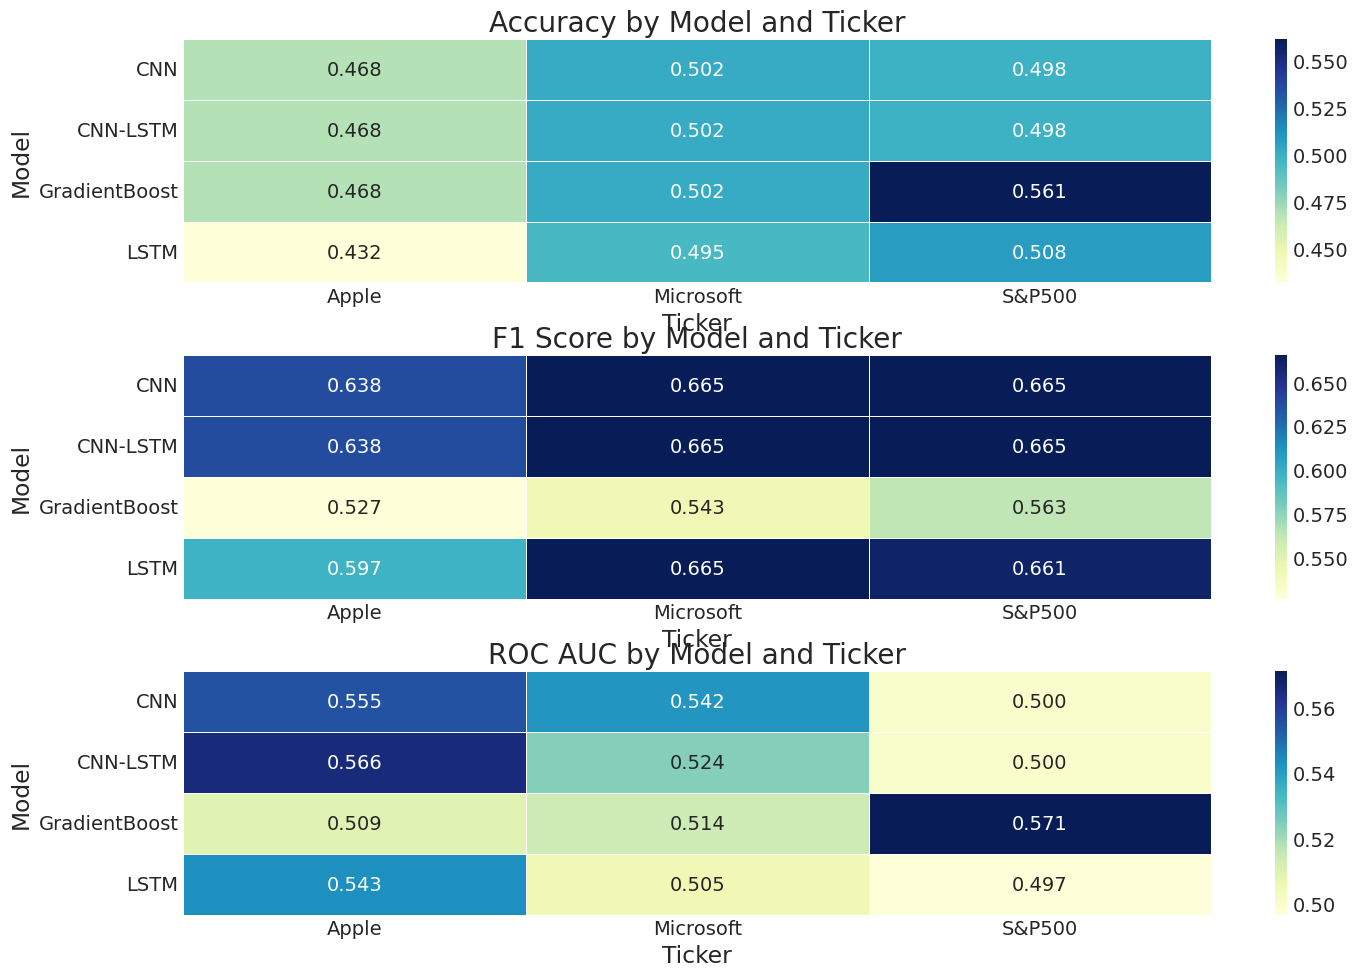

In [19]:
# Final results table
print("\nFinal Results Summary:")
results_data = []

for ticker in tickers.keys():
    # Get GradientBoost results
    ml_acc = ml_results[ticker]['acc']
    ml_f1 = ml_results[ticker]['f1']
    ml_roc = ml_results[ticker]['roc']
    results_data.append({
        'Ticker': ticker,
        'Model': 'GradientBoost',
        'Accuracy': ml_acc,
        'F1 Score': ml_f1,
        'ROC AUC': ml_roc,
        'Best Model': 'GradientBoost' == best_models[ticker]
    })

    # Get LSTM results
    lstm_acc = dl_results[ticker]['acc']
    lstm_f1 = dl_results[ticker]['f1']
    lstm_roc = dl_results[ticker]['roc']
    results_data.append({
        'Ticker': ticker,
        'Model': 'LSTM',
        'Accuracy': lstm_acc,
        'F1 Score': lstm_f1,
        'ROC AUC': lstm_roc,
        'Best Model': 'LSTM' == best_models[ticker]
    })

    # Get CNN results
    cnn_acc = dl_results[ticker]['CNN']['acc']
    cnn_f1 = dl_results[ticker]['CNN']['f1']
    cnn_roc = dl_results[ticker]['CNN']['roc']
    results_data.append({
        'Ticker': ticker,
        'Model': 'CNN',
        'Accuracy': cnn_acc,
        'F1 Score': cnn_f1,
        'ROC AUC': cnn_roc,
        'Best Model': 'CNN' == best_models[ticker]
    })

    # Get CNN-LSTM results
    hybrid_acc = dl_results[ticker]['CNN-LSTM']['acc']
    hybrid_f1 = dl_results[ticker]['CNN-LSTM']['f1']
    hybrid_roc = dl_results[ticker]['CNN-LSTM']['roc']
    results_data.append({
        'Ticker': ticker,
        'Model': 'CNN-LSTM',
        'Accuracy': hybrid_acc,
        'F1 Score': hybrid_f1,
        'ROC AUC': hybrid_roc,
        'Best Model': 'CNN-LSTM' == best_models[ticker]
    })

results_df = pd.DataFrame(results_data)
results_df = results_df.sort_values(['Ticker', 'Accuracy'], ascending=[True, False])

# Format the results table
pd.set_option('display.precision', 3)
display(results_df)

# Create a more visual summary
plt.figure(figsize=(15, 10))

# Plot all metrics by ticker and model
for i, metric in enumerate(['Accuracy', 'F1 Score', 'ROC AUC']):
    plt.subplot(3, 1, i+1)

    pivot_df = results_df.pivot(index='Model', columns='Ticker', values=metric)
    sns.heatmap(pivot_df, annot=True, cmap='YlGnBu', fmt='.3f', linewidths=0.5)

    plt.title(f'{metric} by Model and Ticker')
    plt.tight_layout()

plt.subplots_adjust(hspace=0.3)
plt.show()